In [ ]:
from google.colab import drive
drive.mount("/content/drive")

import os, sys, json, shutil, subprocess, datetime, hashlib, zipfile, ast, glob, importlib
from pathlib import Path

PROJECT = Path("/content/drive/MyDrive/ecg_leak")
for folder in ["src/ecgleak", "notebooks", "data/interim", "data/splits", "data/cache",
               "runs", "results/audit", "results/figures", "gates"]:
    (PROJECT / folder).mkdir(parents=True, exist_ok=True)
(PROJECT / "src/ecgleak/__init__.py").touch()
print("Project folders ready at", PROJECT)

Mounted at /content/drive
Project folders ready at /content/drive/MyDrive/ecg_leak


In [ ]:
!pip install -q wfdb neurokit2 pyyaml

In [ ]:
CONFIG_TEXT = """\
data:
  version: 1.0.3
  raw_dir: /content/drive/MyDrive/PTB-XL
  local_dir: /content/ptbxl
  fs: 500
  record_seconds: 10
  lead: I
  expected_records: 21799
  expected_patients: 18869
qc:
  flat_std_mv: 0.01
  min_beats: 4
  max_beats: 35
cohorts:
  min_records_identity: 2
  identity_train_frac: 0.80
  lockbox_frac: 0.30
  n_folds: 5
  min_test_per_class: 300
preprocess:
  band_hz: [0.5, 40]
  filter_order: 4
  window_s: 2.5
  beat_ms: [-250, 400]
model:
  emb_dim: 256
  cnn_channels: [32, 64, 128]
  kernel: 7
  transformer_layers: 2
  heads: 4
arcface: {s: 30.0, m: 0.50}
train: {epochs: 60, batch: 128, lr: 1.0e-3, weight_decay: 1.0e-4, warmup_frac: 0.05, patience: 10}
leakage:
  n_untrained: 5
  untrained_seeds: [100, 101, 102, 103, 104]
  tasks: [CD, MI, STTC, HYP]
  primary: CD
  C_grid: [0.001, 0.01, 0.1, 1, 10, 100]
stats: {n_boot: 2000, n_perm: 1000, alpha: 0.05, ci_halfwidth_target: 0.03}
seeds: [0, 1, 2]
"""
(PROJECT / "config.yaml").write_text(CONFIG_TEXT)
print("Wrote", PROJECT / "config.yaml")

Wrote /content/drive/MyDrive/ecg_leak/config.yaml


In [ ]:
%%writefile /content/drive/MyDrive/ecg_leak/src/ecgleak/config.py
import datetime, json, os, platform, random
import numpy as np, yaml

DIRS = {'interim': 'data/interim', 'splits': 'data/splits', 'cache': 'data/cache', 'runs': 'runs',
        'results': 'results', 'audit': 'results/audit', 'figures': 'results/figures', 'gates': 'gates'}

def set_seeds(seed, deterministic=False):
    random.seed(seed); np.random.seed(seed); os.environ['PYTHONHASHSEED'] = str(seed)
    try:
        import torch
        torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
        if deterministic:
            torch.backends.cudnn.deterministic = True; torch.backends.cudnn.benchmark = False
    except ImportError:
        pass

def environment():
    env = {'python': platform.python_version(), 'numpy': np.__version__,
           'time': datetime.datetime.now().isoformat(timespec='seconds')}
    try:
        import torch
        env.update(torch=torch.__version__, cuda=torch.cuda.is_available(),
                   gpu=torch.cuda.get_device_name(0) if torch.cuda.is_available() else None)
    except ImportError:
        env['torch'] = None
    return env

def load(path, seed=None, verbose=True):
    with open(path) as f:
        cfg = yaml.safe_load(f)
    root = os.path.dirname(os.path.abspath(path))
    cfg['paths'] = {'root': root, 'raw': cfg['data']['raw_dir'], 'local_data': cfg['data']['local_dir'],
                    **{k: os.path.join(root, v) for k, v in DIRS.items()}}
    cfg['seed'] = cfg['seeds'][0] if seed is None else seed
    set_seeds(cfg['seed'])
    if verbose:
        e = environment()
        print(f"Root {root} | raw data {cfg['paths']['raw']} | seed {cfg['seed']} | "
              f"Python {e['python']} | torch {e.get('torch')} | GPU {e.get('gpu') or 'none (CPU)'}")
    return cfg

def freeze(cfg, run_dir):
    os.makedirs(run_dir, exist_ok=True)
    with open(os.path.join(run_dir, 'config.frozen.yaml'), 'w') as f:
        yaml.safe_dump({k: v for k, v in cfg.items() if k != 'paths'}, f, sort_keys=False)
    with open(os.path.join(run_dir, 'environment.json'), 'w') as f:
        json.dump(environment(), f, indent=2)

Overwriting /content/drive/MyDrive/ecg_leak/src/ecgleak/config.py


In [ ]:
import os, sys, json, shutil, subprocess, datetime, hashlib, zipfile, ast, glob, importlib
from pathlib import Path
PROJECT = Path("/content/drive/MyDrive/ecg_leak")
if not PROJECT.is_dir():
    from google.colab import drive
    drive.mount("/content/drive")

sys.path.insert(0, str(PROJECT / "src"))
import ecgleak.config as ecfg
importlib.reload(ecfg)

CFG = ecfg.load(str(PROJECT / "config.yaml"))
PATHS = CFG["paths"]
RAW = PATHS["raw"].rstrip("/") + "/"
LOCAL = CFG["data"]["local_dir"].rstrip("/") + "/"
os.makedirs(LOCAL, exist_ok=True)

def free_gb(p):
    return shutil.disk_usage(p).free / 1e9

n_sub = len([d for d in os.listdir(RAW + "records500") if os.path.isdir(RAW + "records500/" + d)]) \
        if os.path.isdir(RAW + "records500") else 0
checks0 = {
    "Project folder on Drive": PROJECT.is_dir(),
    "PTB-XL folder found (My Drive/PTB-XL)": os.path.isdir(RAW),
    "records500/ present": os.path.isdir(RAW + "records500"),
    "ptbxl_database.csv present": os.path.isfile(RAW + "ptbxl_database.csv"),
    "scp_statements.csv present": os.path.isfile(RAW + "scp_statements.csv"),
    "SHA256SUMS.txt present": os.path.isfile(RAW + "SHA256SUMS.txt"),
    "Colab disk >= 6 GB free": free_gb(LOCAL) >= 6,
}
for name, ok in checks0.items():
    print(f"  {'PASS' if ok else 'FAIL'}  {name}")
print(f"records500 subfolders: {n_sub} (PTB-XL 1.0.3 has 22: 00000 ... 21000)")
assert all(checks0.values()), "Phase 0 gate failed: fix the FAIL lines above"
print("PHASE 0: GO")

Root /content/drive/MyDrive/ecg_leak | raw data /content/drive/MyDrive/PTB-XL | seed 0 | Python 3.13.16 | torch 2.11.0+cu130 | GPU Tesla T4
  PASS  Project folder on Drive
  PASS  PTB-XL folder found (My Drive/PTB-XL)
  PASS  records500/ present
  PASS  ptbxl_database.csv present
  PASS  scp_statements.csv present
  PASS  SHA256SUMS.txt present
  PASS  Colab disk >= 6 GB free
records500 subfolders: 22 (PTB-XL 1.0.3 has 22: 00000 ... 21000)
PHASE 0: GO


Cell 1.1: Copy records500 and the CSVs from Drive to the Colab disk. This takes about 10–25 minutes. If Colab disconnects, re-run it and it copies only the files that are still missing.

In [ ]:
from tqdm.auto import tqdm
from concurrent.futures import ThreadPoolExecutor
WAVE_DIR, FILE_COL = "records500", "filename_hr"
KEEP = ("ptbxl_database.csv", "scp_statements.csv", "SHA256SUMS.txt", "LICENSE.txt", "RECORDS")
RAW = PATHS["raw"].rstrip("/") + "/"
P = LOCAL

def sha256(path, chunk=1 << 22):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(chunk), b""):
            h.update(block)
    return h.hexdigest()

for name in KEEP:
    if os.path.isfile(RAW + name):
        shutil.copyfile(RAW + name, P + name)

jobs = []
for sub in sorted(os.listdir(RAW + WAVE_DIR)):
    if os.path.isdir(RAW + WAVE_DIR + "/" + sub):
        os.makedirs(P + WAVE_DIR + "/" + sub, exist_ok=True)
        jobs += [f"{WAVE_DIR}/{sub}/{f}" for f in os.listdir(RAW + WAVE_DIR + "/" + sub)]
todo = [r for r in jobs if not (os.path.isfile(P + r) and os.path.getsize(P + r) == os.path.getsize(RAW + r))]
print(f"Files in Drive records500: {len(jobs):,} | still to copy: {len(todo):,}")

def copy_one(rel):
    shutil.copyfile(RAW + rel, P + rel)

with ThreadPoolExecutor(max_workers=32) as pool:            # parallel: Drive is slow per file, fast in bulk
    list(tqdm(pool.map(copy_one, todo), total=len(todo), desc="Copying to Colab disk", mininterval=10))
print("Ready on the Colab disk:", P)
SOURCE = RAW

Files in Drive records500: 43,599 | still to copy: 43,599


Copying to Colab disk:   0%|          | 0/43599 [00:00<?, ?it/s]

Ready on the Colab disk: /content/ptbxl/


Cell 1.2: Check every file against PhysioNet’s checksums (about 1–2 minutes)

In [ ]:
import pandas as pd, numpy as np
published = {}
for line in open(P + "SHA256SUMS.txt"):
    parts = line.strip().split(maxsplit=1)
    if len(parts) == 2:
        published[parts[1].lstrip("*").removeprefix("./")] = parts[0].lower()
targets = [r for r in published if r in KEEP[:2] or r.startswith(WAVE_DIR + "/")]
status = pd.Series({r: ("missing" if not os.path.isfile(P + r) else
                        ("ok" if sha256(P + r) == published[r] else "MISMATCH"))
                    for r in tqdm(targets, desc="SHA-256", mininterval=10)}, dtype=object)
print(status.value_counts().to_string())
status[status != "ok"].to_csv(f"{PATHS['audit']}/phase1_checksum_problems.csv")
CHECKSUMS_OK = len(status) > 0 and bool((status == "ok").all())
if not CHECKSUMS_OK:
    print("Problem files are listed in results/audit/phase1_checksum_problems.csv")

SHA-256:   0%|          | 0/43600 [00:00<?, ?it/s]

ok    43600


In [ ]:
db = pd.read_csv(P + "ptbxl_database.csv", index_col="ecg_id")
N_REC, N_PAT = len(db), db["patient_id"].nunique()
VERSION_OK = (N_REC, N_PAT) == (CFG["data"]["expected_records"], CFG["data"]["expected_patients"])
print(f"Records {N_REC:,} | Patients {N_PAT:,} | matches 1.0.3: {VERSION_OK}")

missing = [s + e for s in db[FILE_COL] for e in (".dat", ".hea") if not os.path.isfile(P + s + e)]
COMPLETE = not missing
print("Missing waveform files:", len(missing))

REQUIRED = ["patient_id", "recording_date", "scp_codes", "age", "sex", FILE_COL]
COLUMNS_OK = all(c in db.columns for c in REQUIRED)
print("Required columns present:", COLUMNS_OK)

Records 21,799 | Patients 18,869 | matches 1.0.3: True
Missing waveform files: 0
Required columns present: True


Cell 1.4: Read lead I from every record (about 3–5 minutes)

In [ ]:
import wfdb
FS = CFG["data"]["fs"]
N_SAMP = FS * CFG["data"]["record_seconds"]

lead_I = np.full((N_REC, N_SAMP), np.nan, dtype=np.float32)
read_err = {}
for i, (ecg_id, stem) in enumerate(tqdm(db[FILE_COL].items(), total=N_REC, desc="Reading lead I", mininterval=10)):
    try:
        rec = wfdb.rdrecord(P + stem, channel_names=["I"])
        if rec.fs == FS and rec.sig_len == N_SAMP:
            lead_I[i] = rec.p_signal[:, 0]
        else:
            read_err[ecg_id] = f"fs={rec.fs}, len={rec.sig_len}"
    except Exception as e:
        read_err[ecg_id] = type(e).__name__
print(f"Read {N_REC - len(read_err):,} records | problems: {len(read_err)}")

Reading lead I:   0%|          | 0/21799 [00:00<?, ?it/s]

Read 21,799 records | problems: 0


In [ ]:
SUPER = ["NORM", "MI", "STTC", "CD", "HYP"]
scp = pd.read_csv(P + "scp_statements.csv", index_col=0)
diag_class = scp.loc[scp["diagnostic"] == 1, "diagnostic_class"]

def superclasses(codes_text):
    codes = ast.literal_eval(codes_text)
    return {diag_class[c] for c in codes if c in diag_class.index}

sets = db["scp_codes"].map(superclasses)
labels = pd.DataFrame({c: sets.map(lambda s, c=c: int(c in s)) for c in SUPER}, index=db.index)
labels.to_csv(f"{PATHS['interim']}/labels_superclass.csv")
print("Records per superclass:\n" + labels.sum().to_string())
print("Records with no diagnostic superclass:", int((labels.sum(axis=1) == 0).sum()))

Records per superclass:
NORM    9514
MI      5469
STTC    5235
CD      4898
HYP     2649
Records with no diagnostic superclass: 411


Cell 1.6: Filter, find R-peaks, compute median beats, quality check (about 5–10 minutes)

In [ ]:
import neurokit2 as nk
from scipy.signal import butter, sosfiltfilt

lo, hi = CFG["preprocess"]["band_hz"]
sos = butter(CFG["preprocess"]["filter_order"], [lo, hi], btype="band", fs=FS, output="sos")
b0, b1 = [int(round(ms * FS / 1000)) for ms in CFG["preprocess"]["beat_ms"]]   # -125, 200 samples
BEAT_LEN = b1 - b0

ok_read = np.isfinite(lead_I).all(axis=1)
filtered = np.zeros_like(lead_I)
filtered[ok_read] = sosfiltfilt(sos, lead_I[ok_read], axis=1)
raw_std = np.nanstd(lead_I, axis=1)

median_beats = np.full((N_REC, BEAT_LEN), np.nan, dtype=np.float32)
MAX_PEAKS = 40
rpeaks = np.full((N_REC, MAX_PEAKS), -1, dtype=np.int32)
n_beats = np.zeros(N_REC, dtype=int)
for i in tqdm(np.where(ok_read & (raw_std > CFG["qc"]["flat_std_mv"]))[0], desc="R-peaks", mininterval=10):
    try:
        _, info = nk.ecg_peaks(filtered[i], sampling_rate=FS)
        pk = np.asarray(info["ECG_R_Peaks"], dtype=int)
    except Exception:
        continue
    n_beats[i] = len(pk)
    rpeaks[i, :min(len(pk), MAX_PEAKS)] = pk[:MAX_PEAKS]
    full = pk[(pk + b0 >= 0) & (pk + b1 <= N_SAMP)]
    if len(full):
        median_beats[i] = np.median(np.stack([filtered[i, p + b0:p + b1] for p in full]), axis=0)

std_f = filtered.std(axis=1, keepdims=True)
signals = ((filtered - filtered.mean(axis=1, keepdims=True)) / np.where(std_f > 0, std_f, 1)).astype(np.float16)

reason = pd.Series("", index=db.index, dtype=object)
reason[~ok_read] = "unreadable"
reason[(reason == "") & (raw_std <= CFG["qc"]["flat_std_mv"])] = "flat lead I"
reason[(reason == "") & ((n_beats < CFG["qc"]["min_beats"]) | (n_beats > CFG["qc"]["max_beats"]))] = "implausible beat count"
reason[(reason == "") & ~np.isfinite(median_beats).all(axis=1)] = "no full beat"
QC_PASS = (reason == "").to_numpy()
reason[reason != ""].rename("reason").to_csv(f"{PATHS['audit']}/phase1_excluded.csv")
print(f"QC pass: {QC_PASS.sum():,} / {N_REC:,}")
print(reason[reason != ""].value_counts().to_string())

R-peaks:   0%|          | 0/21799 [00:00<?, ?it/s]

QC pass: 21,798 / 21,799
implausible beat count    1


In [ ]:
rng = np.random.default_rng(CFG["seed"])
meta = db[["patient_id", "recording_date", "age", "sex"]].copy()
meta["patient_id"] = meta["patient_id"].astype(int)
meta["qc_pass"] = QC_PASS
per_patient = meta.groupby("patient_id").size()          # counted before QC, so cohorts never shift with QC

id_pats = np.array(sorted(per_patient[per_patient >= CFG["cohorts"]["min_records_identity"]].index))
probe_pats = np.array(sorted(per_patient[per_patient == 1].index))

rng.shuffle(id_pats)
n_train = int(round(CFG["cohorts"]["identity_train_frac"] * len(id_pats)))
split_of = {p: "id_train" for p in id_pats[:n_train]}
split_of.update({p: "id_eval" for p in id_pats[n_train:]})

# Probe cohort: stratify on the label pattern, then 30% lockbox and 5 folds in probe-dev.
probe_meta = meta[meta["patient_id"].isin(probe_pats)].join(labels)
key = probe_meta[SUPER].astype(str).agg("".join, axis=1)
counts = key.value_counts()
key = key.where(key.map(counts) >= 10, "rare")
fold_of = {}
for _, grp in probe_meta.groupby(key):
    pats = grp["patient_id"].to_numpy().copy()
    rng.shuffle(pats)
    n_lock = int(round(CFG["cohorts"]["lockbox_frac"] * len(pats)))
    for p in pats[:n_lock]:
        split_of[p] = "lockbox"
    for j, p in enumerate(pats[n_lock:]):
        split_of[p] = "probe_dev"
        fold_of[p] = j % CFG["cohorts"]["n_folds"]

meta["split"] = meta["patient_id"].map(split_of)
meta["fold"] = meta["patient_id"].map(fold_of).fillna(-1).astype(int)
splits = meta.join(labels)
splits.to_csv(f"{PATHS['splits']}/splits.csv")
SPLITS_SHA = sha256(f"{PATHS['splits']}/splits.csv")

pats_by_split = {s: set(g["patient_id"]) for s, g in splits.groupby("split")}
names = list(pats_by_split)
OVERLAP = sum(len(pats_by_split[a] & pats_by_split[b]) for i, a in enumerate(names) for b in names[i + 1:])
used = splits[splits["qc_pass"]]
print(used.groupby("split").agg(records=("patient_id", "size"), patients=("patient_id", "nunique")).to_string())
print("Patients in more than one split:", OVERLAP)

def task_counts(df, cls):
    pos = df[cls] == 1
    neg = (df["NORM"] == 1) & (df[SUPER].sum(axis=1) == 1)
    return int(pos.sum()), int(neg.sum())

lock = used[used["split"] == "lockbox"]
task_table = pd.DataFrame({c: task_counts(lock, c) for c in CFG["leakage"]["tasks"]}, index=["positive", "NORM-only"]).T
print("\nLockbox patients per task:\n" + task_table.to_string())
task_table.to_csv(f"{PATHS['audit']}/phase1_lockbox_task_counts.csv")
PRIMARY_OK = min(task_counts(lock, CFG["leakage"]["primary"])) >= CFG["cohorts"]["min_test_per_class"]

           records  patients
split                       
id_eval        994       422
id_train      4047      1689
lockbox       5029      5029
probe_dev    11728     11728
Patients in more than one split: 0

Lockbox patients per task:
      positive  NORM-only
CD        1072       2300
MI        1124       2300
STTC      1102       2300
HYP        583       2300


In [ ]:
idc = splits[splits["split"].isin(["id_train", "id_eval"]) & splits["qc_pass"]].copy()
idc["date"] = pd.to_datetime(idc["recording_date"], errors="coerce")
idc = idc.sort_values(["patient_id", "date"])
nxt = idc.groupby("patient_id")[SUPER].shift(-1)
pairs = idc[SUPER][nxt.notna().all(axis=1)]
nxt = nxt.dropna()
persist = pd.DataFrame({c: {"visit-1 positives": int(pairs[c].sum()),
                            "still positive at next visit": int(((pairs[c] == 1) & (nxt[c] == 1)).sum())}
                        for c in SUPER}).T
persist["persistence"] = (persist["still positive at next visit"] / persist["visit-1 positives"].replace(0, np.nan)).round(3)
persist.to_csv(f"{PATHS['interim']}/persistence.csv")
print(f"Consecutive visit pairs: {len(pairs):,}\n" + persist.to_string())

Consecutive visit pairs: 2,930
      visit-1 positives  still positive at next visit  persistence
NORM                821                           598        0.728
MI                 1001                           767        0.766
STTC                910                           611        0.671
CD                  787                           569        0.723
HYP                 408                           251        0.615


id_train    4,047 records -> /content/drive/MyDrive/ecg_leak/data/cache/id_train.npz
id_eval       994 records -> /content/drive/MyDrive/ecg_leak/data/cache/id_eval.npz
probe_dev  11,728 records -> /content/drive/MyDrive/ecg_leak/data/cache/probe_dev.npz
lockbox     5,029 records -> /content/drive/MyDrive/ecg_leak/data/cache/lockbox.npz


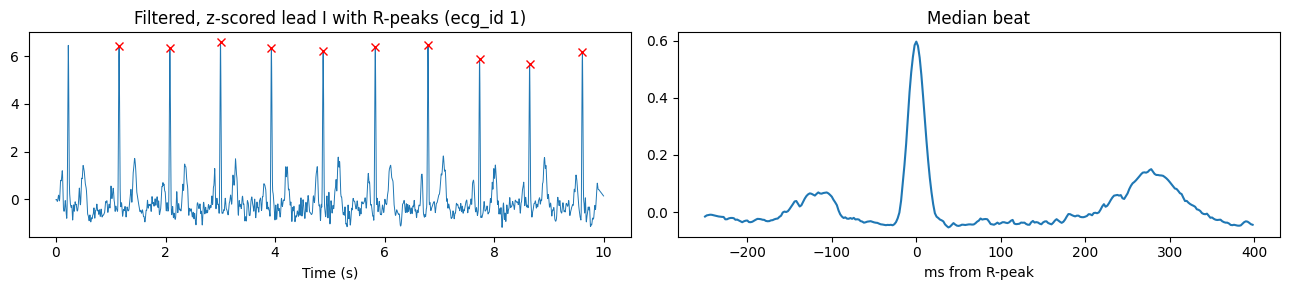

In [ ]:
CACHE = PATHS["cache"]
age = db["age"].to_numpy(dtype=float)
sex = db["sex"].to_numpy(dtype=float)
split_arr = splits["split"].to_numpy()
cache_files = {}
for s in ["id_train", "id_eval", "probe_dev", "lockbox"]:
    m = (split_arr == s) & QC_PASS
    path = f"{CACHE}/{s}.npz"
    np.savez(path, ecg_id=db.index.to_numpy()[m], patient_id=splits["patient_id"].to_numpy()[m],
             fold=splits["fold"].to_numpy()[m], signal=signals[m], rpeaks=rpeaks[m],
             median_beat=median_beats[m], labels=labels.to_numpy()[m], label_names=np.array(SUPER),
             age=age[m], sex=sex[m])
    cache_files[s] = {"records": int(m.sum()), "sha256": sha256(path)}
    print(f"{s:10s} {int(m.sum()):6,} records -> {path}")

import matplotlib.pyplot as plt
i = int(np.where(QC_PASS)[0][0])
t = np.arange(BEAT_LEN) / FS * 1000 + CFG["preprocess"]["beat_ms"][0]
fig, ax = plt.subplots(1, 2, figsize=(13, 3))
ax[0].plot(np.arange(N_SAMP) / FS, signals[i].astype(float), lw=0.7)
pk = rpeaks[i][rpeaks[i] >= 0]
ax[0].plot(pk / FS, signals[i][pk].astype(float), "rx")
ax[0].set_title(f"Filtered, z-scored lead I with R-peaks (ecg_id {db.index[i]})"); ax[0].set_xlabel("Time (s)")
ax[1].plot(t, median_beats[i]); ax[1].set_title("Median beat"); ax[1].set_xlabel("ms from R-peak")
plt.tight_layout(); plt.savefig(f"{PATHS['figures']}/phase1_preprocessing_example.png", dpi=150); plt.show()

In [ ]:
gate = {"Checksums (all files)": CHECKSUMS_OK, "Version 1.0.3": VERSION_OK, "Completeness": COMPLETE,
        "Metadata columns": COLUMNS_OK, "No patient in two splits": OVERLAP == 0,
        f"Lockbox >= {CFG['cohorts']['min_test_per_class']} per class ({CFG['leakage']['primary']} vs NORM)": PRIMARY_OK,
        "Cache written": all(v["records"] > 0 for v in cache_files.values())}
GO = all(gate.values())
print("PHASE 1 GATE\n" + "-" * 50)
for k, v in gate.items():
    print(f"  {'PASS' if v else 'FAIL'}  {k}")
print("-" * 50)
print("GO: Phase 1 complete. Next: Phase 2 (baselines + pilot)." if GO else "NO-GO: fix the FAIL lines above.")
json.dump({"phase": 1, "go": GO, "checks": gate, "records": N_REC, "patients": N_PAT,
           "qc_pass": int(QC_PASS.sum()), "source": SOURCE, "splits_sha256": SPLITS_SHA,
           "cache": cache_files, "environment": ecfg.environment()},
          open(f"{PATHS['gates']}/gate_1.json", "w"), indent=2, default=str)

PHASE 1 GATE
--------------------------------------------------
  PASS  Checksums (all files)
  PASS  Version 1.0.3
  PASS  Completeness
  PASS  Metadata columns
  PASS  No patient in two splits
  PASS  Lockbox >= 300 per class (CD vs NORM)
  PASS  Cache written
--------------------------------------------------
GO: Phase 1 complete. Next: Phase 2 (baselines + pilot).


Cell 2.0: Start the session

What: connects Drive, loads the config, confirms Phase 1 passed, and checks for a GPU.
Why: every phase starts from the same settings and refuses to run if the previous phase didn’t pass.

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

import os, sys, json, shutil, importlib, time, math
from pathlib import Path
import numpy as np, pandas as pd, torch

PROJECT = Path("/content/drive/MyDrive/ecg_leak")
sys.path.insert(0, str(PROJECT / "src"))
import ecgleak.config as ecfg
importlib.reload(ecfg)
CFG = ecfg.load(str(PROJECT / "config.yaml"))
PATHS = CFG["paths"]

gate1 = json.load(open(f"{PATHS['gates']}/gate_1.json"))
assert gate1["go"], "Phase 1 gate is not GO: finish Phase 1 first"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Phase 1 gate: GO | Device:", DEVICE,
      "|", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "no GPU: Runtime > Change runtime type > T4 GPU")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Root /content/drive/MyDrive/ecg_leak | raw data /content/drive/MyDrive/PTB-XL | seed 0 | Python 3.13.16 | torch 2.11.0+cu130 | GPU Tesla T4
Phase 1 gate: GO | Device: cuda | Tesla T4


Cell 2.1: Load the heartbeat cache

What: copies the Phase 1 cache files from Drive to Colab’s disk and loads them, along with each record’s date.
Why: reading from local disk is fast. The dates tell us each patient’s first visit for the identity test. The lockbox file isn’t loaded at all, so it can’t be peeked at by accident.

In [ ]:
LOCAL_CACHE = "/content/cache"
os.makedirs(LOCAL_CACHE, exist_ok=True)
splits = pd.read_csv(f"{PATHS['splits']}/splits.csv", index_col="ecg_id")
D = {}
for s in ["id_train", "id_eval", "probe_dev"]:          # lockbox stays sealed until Phase 3
    src, dst = f"{PATHS['cache']}/{s}.npz", f"{LOCAL_CACHE}/{s}.npz"
    if not os.path.isfile(dst):
        shutil.copyfile(src, dst)
    z = np.load(dst, allow_pickle=False)
    D[s] = {k: z[k] for k in z.files}
    D[s]["date"] = pd.to_datetime(splits.loc[D[s]["ecg_id"], "recording_date"]).to_numpy()
    print(f"{s:10s} records {len(D[s]['ecg_id']):6,} | patients {len(np.unique(D[s]['patient_id'])):5,} | signal {D[s]['signal'].shape}")
SUPER = list(D["probe_dev"]["label_names"])

id_train   records  4,047 | patients 1,689 | signal (4047, 5000)
id_eval    records    994 | patients   422 | signal (994, 5000)
probe_dev  records 11,728 | patients 11,728 | signal (11728, 5000)


Cell 2.2: Model code (models.py)

What: defines the encoder, which turns a 2.5 s heartbeat window into a 256-number “fingerprint” (the template). It also defines the ArcFace head used to train it to recognise people, and a function that makes untrained copies.
Why: one architecture is used for every comparison. Any difference between the trained model and its untrained copies then comes from identity training, not from the network design.

In [ ]:
%%writefile /content/drive/MyDrive/ecg_leak/src/ecgleak/models.py
import math
import torch, torch.nn as nn, torch.nn.functional as F

class ECGEncoder(nn.Module):
    """1-lead ECG window (B x 1250) -> 256-d unit vector (the template)."""
    def __init__(self, channels=(32, 64, 128), kernel=7, layers=2, heads=4, emb_dim=256, max_len=1024):
        super().__init__()
        blocks, c_in = [], 1
        for c in channels:
            blocks += [nn.Conv1d(c_in, c, kernel, padding=kernel // 2), nn.BatchNorm1d(c), nn.GELU(), nn.MaxPool1d(2)]
            c_in = c
        self.stem = nn.Sequential(*blocks)
        d = channels[-1]
        self.pos = nn.Parameter(torch.randn(1, max_len, d) * 0.02)
        layer = nn.TransformerEncoderLayer(d, heads, dim_feedforward=4 * d, dropout=0.1,
                                           activation="gelu", batch_first=True)
        self.transformer = nn.TransformerEncoder(layer, layers, enable_nested_tensor=False)
        self.proj = nn.Linear(d, emb_dim)
        self.emb_dim = emb_dim

    def forward(self, x):
        if x.dim() == 2:
            x = x.unsqueeze(1)
        h = self.stem(x).transpose(1, 2)
        h = self.transformer(h + self.pos[:, :h.size(1)])
        return F.normalize(self.proj(h.mean(dim=1)), dim=1)

class ArcFaceHead(nn.Module):
    """Additive angular margin: pushes each person's templates into a tight cone."""
    def __init__(self, emb_dim, n_classes, s=30.0, m=0.5):
        super().__init__()
        self.W = nn.Parameter(torch.randn(n_classes, emb_dim) * 0.01)
        self.s, self.m = s, m
        self.th, self.mm = math.cos(math.pi - m), math.sin(math.pi - m) * m

    def forward(self, emb, y):
        cos = F.linear(emb, F.normalize(self.W, dim=1)).clamp(-1 + 1e-7, 1 - 1e-7)
        t = cos.gather(1, y[:, None])
        with_margin = torch.cos(torch.acos(t) + self.m)
        t_new = torch.where(t > self.th, with_margin, t - self.mm)
        return self.s * cos.scatter(1, y[:, None], t_new)

def build_encoder(cfg):
    m = cfg["model"]
    return ECGEncoder(m["cnn_channels"], m["kernel"], m["transformer_layers"], m["heads"], m["emb_dim"])

def untrained_copies(cfg, seeds, device):
    """Same architecture, random weights, never trained: the baseline for Delta_rand."""
    out = []
    for s in seeds:
        torch.manual_seed(s)
        out.append(build_encoder(cfg).to(device).eval())
    return out

Overwriting /content/drive/MyDrive/ecg_leak/src/ecgleak/models.py


Cell 2.3: Training code (train.py)

What: the training loop. It takes random 2.5 s crops with small amplitude and noise changes, uses mixed precision on the GPU, saves a checkpoint to Drive after every epoch, resumes automatically, and stops early when identity accuracy stops improving.
Why: free Colab disconnects. With a checkpoint every epoch you lose at most one epoch, and re-running the cell simply continues the run. Diagnosis labels are never used here, only patient IDs

In [ ]:
%%writefile /content/drive/MyDrive/ecg_leak/src/ecgleak/train.py
import glob, math, os, time
import numpy as np, torch, torch.nn.functional as F
from .models import build_encoder, ArcFaceHead

def _schedule(opt, total, warm):
    def f(step):
        if step < warm:
            return (step + 1) / max(1, warm)
        return 0.5 * (1 + math.cos(math.pi * min(1.0, (step - warm) / max(1, total - warm))))
    return torch.optim.lr_scheduler.LambdaLR(opt, f)

def latest_checkpoint(run_dir):
    files = sorted(glob.glob(os.path.join(run_dir, "checkpoints", "epoch_*.pt")))
    return files[-1] if files else None

def train_identity(cfg, signals, patient_ids, run_dir, device, epochs=None, eval_fn=None, crops_per_record=4,
                   seed=None, stop_after=None, max_steps_per_epoch=None, log=print):
    """ArcFace identity training with an automatic resume from the newest checkpoint in run_dir."""
    t, seed = cfg["train"], cfg["seed"] if seed is None else seed
    epochs = epochs or t["epochs"]
    window = int(cfg["preprocess"]["window_s"] * cfg["data"]["fs"])
    classes, y_all = np.unique(patient_ids, return_inverse=True)
    n, L, B = len(signals), signals.shape[1], t["batch"]
    steps = math.ceil(n * crops_per_record / B)
    if max_steps_per_epoch:
        steps = min(steps, max_steps_per_epoch)

    torch.manual_seed(seed)
    model = build_encoder(cfg).to(device)
    head = ArcFaceHead(cfg["model"]["emb_dim"], len(classes), cfg["arcface"]["s"], cfg["arcface"]["m"]).to(device)
    opt = torch.optim.AdamW(list(model.parameters()) + list(head.parameters()), lr=t["lr"], weight_decay=t["weight_decay"])
    sched = _schedule(opt, steps * epochs, int(t["warmup_frac"] * steps * epochs))
    scaler = torch.amp.GradScaler("cuda", enabled=(device == "cuda"))
    os.makedirs(os.path.join(run_dir, "checkpoints"), exist_ok=True)

    start, history, best, bad = 0, [], float("inf"), 0
    ck = latest_checkpoint(run_dir)
    if ck:
        st = torch.load(ck, map_location=device, weights_only=False)
        model.load_state_dict(st["model"]); head.load_state_dict(st["head"])
        opt.load_state_dict(st["opt"]); sched.load_state_dict(st["sched"]); scaler.load_state_dict(st["scaler"])
        torch.set_rng_state(st["torch_rng"].cpu())
        if device == "cuda" and st.get("cuda_rng") is not None:
            torch.cuda.set_rng_state_all([s.cpu() for s in st["cuda_rng"]])
        start, history, best, bad = st["epoch"] + 1, st["history"], st["best"], st["bad"]
        log(f"Resumed from {os.path.basename(ck)} -> continuing at epoch {start + 1}")

    for epoch in range(start, epochs):
        t0 = time.time()
        model.train(); head.train()
        rng = np.random.default_rng(seed * 1000 + epoch)
        idx = np.repeat(np.arange(n), crops_per_record); rng.shuffle(idx)
        offs = rng.integers(0, L - window + 1, size=len(idx))
        scale = rng.uniform(0.9, 1.1, size=len(idx))
        tot_loss = tot_acc = 0.0
        for b in range(steps):
            sl = slice(b * B, (b + 1) * B)
            ii = idx[sl]
            xb = np.stack([signals[i, o:o + window] for i, o in zip(ii, offs[sl])]).astype(np.float32)
            xb = (xb * scale[sl, None] + rng.normal(0, 0.05, xb.shape)).astype(np.float32)
            xb = torch.from_numpy(xb).to(device)
            yb = torch.from_numpy(y_all[ii]).long().to(device)
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=(device == "cuda")):
                emb = model(xb)
            logits = head(emb.float(), yb)
            loss = F.cross_entropy(logits, yb)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(list(model.parameters()) + list(head.parameters()), 5.0)
            scaler.step(opt); scaler.update(); sched.step()
            tot_loss += loss.item()
            tot_acc += (logits.argmax(1) == yb).float().mean().item()
        rec = {"epoch": epoch + 1, "loss": tot_loss / steps, "train_acc": tot_acc / steps,
               "lr": sched.get_last_lr()[0], "seconds": round(time.time() - t0, 1)}
        if eval_fn is not None:
            rec.update(eval_fn(model))
        improved = rec.get("eer", -epoch) < best
        if improved:
            best, bad = rec.get("eer", -epoch), 0
            torch.save({"model": model.state_dict(), "epoch": epoch + 1, "eer": rec.get("eer")},
                       os.path.join(run_dir, "best.pt"))
        else:
            bad += 1
        history.append(rec)
        path = os.path.join(run_dir, "checkpoints", f"epoch_{epoch + 1:03d}.pt")
        torch.save({"epoch": epoch, "model": model.state_dict(), "head": head.state_dict(), "opt": opt.state_dict(),
                    "sched": sched.state_dict(), "scaler": scaler.state_dict(), "history": history, "best": best,
                    "bad": bad, "torch_rng": torch.get_rng_state(),
                    "cuda_rng": torch.cuda.get_rng_state_all() if device == "cuda" else None}, path + ".tmp")
        os.replace(path + ".tmp", path)
        for old in sorted(glob.glob(os.path.join(run_dir, "checkpoints", "epoch_*.pt")))[:-3]:
            os.remove(old)
        log(" | ".join(f"{k} {v:.4f}" if isinstance(v, float) else f"{k} {v}" for k, v in rec.items()))
        if stop_after is not None and epoch + 1 >= stop_after:
            break
        if bad >= t["patience"]:
            log("Early stopping: identity EER stopped improving")
            break
    return model, history

def load_best(cfg, run_dir, device):
    model = build_encoder(cfg).to(device)
    st = torch.load(os.path.join(run_dir, "best.pt"), map_location=device, weights_only=False)
    model.load_state_dict(st["model"])
    return model.eval(), st

Overwriting /content/drive/MyDrive/ecg_leak/src/ecgleak/train.py


Cell 2.4: Evaluation code (evaluate.py)

What: functions that make a template for each record and measure identity accuracy. EER is the error rate where false accepts equal false rejects, so lower is better. It also defines the diagnosis “attacker”, a simple logistic regression scored by AUROC.
Why: Phase 2, Phase 3 and every later phase use these same functions. A number from one phase can then be compared fairly with any other.

In [ ]:
%%writefile /content/drive/MyDrive/ecg_leak/src/ecgleak/evaluate.py
import warnings
import numpy as np, torch, torch.nn.functional as F
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegressionCV
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
warnings.filterwarnings("ignore", category=FutureWarning, module="sklearn")

@torch.no_grad()
def embed(model, signals, window, device, batch=256):
    """Template = mean of the embeddings of non-overlapping windows, L2-normalised."""
    model.eval()
    n_win = signals.shape[1] // window
    out = []
    for i in range(0, len(signals), batch):
        x = torch.from_numpy(signals[i:i + batch, :n_win * window].astype(np.float32)).to(device)
        e = model(x.reshape(-1, window)).reshape(-1, n_win, model.emb_dim).mean(1)
        out.append(F.normalize(e, dim=1).cpu().numpy())
    return np.concatenate(out)

def unit_rows(X):
    X = (X - X.mean(1, keepdims=True)) / (X.std(1, keepdims=True) + 1e-8)
    return X / (np.linalg.norm(X, axis=1, keepdims=True) + 1e-8)

def eer(genuine, impostor):
    y = np.r_[np.ones(len(genuine)), np.zeros(len(impostor))]
    fpr, tpr, _ = roc_curve(y, np.r_[genuine, impostor])
    i = np.nanargmin(np.abs((1 - tpr) - fpr))
    return float((fpr[i] + 1 - tpr[i]) / 2)

def verification(emb, patient_ids, dates):
    """Enroll each patient's earliest record; verify their later records against every enrolled patient."""
    order = np.lexsort((dates.astype("datetime64[ns]").astype(np.int64), patient_ids))
    seen, enroll, probe = set(), [], []
    for i in order:
        (probe if patient_ids[i] in seen else enroll).append(i)
        seen.add(patient_ids[i])
    E, P = emb[enroll], emb[probe]
    S = P @ E.T
    same = patient_ids[probe][:, None] == patient_ids[enroll][None, :]
    rank1 = float(np.mean(patient_ids[enroll][S.argmax(1)] == patient_ids[probe]))
    return {"eer": eer(S[same], S[~same]), "rank1": rank1, "n_enrolled": len(enroll), "n_probes": len(probe)}

def task_data(labels, names, cls):
    """Positives carry the class; negatives are NORM-only records."""
    names = list(names)
    pos = labels[:, names.index(cls)] == 1
    neg = (labels[:, names.index("NORM")] == 1) & (labels.sum(1) == 1)
    keep = pos | neg
    return keep, pos[keep].astype(int)

def demo_features(age, sex):
    a = np.where(np.isfinite(age), np.clip(age, 0, 90), np.nan)
    a = np.where(np.isnan(a), np.nanmedian(a), a)
    s = np.where(np.isfinite(sex), sex, 0.5)
    return np.c_[a, s]

def cv_auroc(X, y, folds, C_grid, pca=None, seed=0):
    """Out-of-fold AUROC over the given patient folds; C chosen by inner 3-fold CV on training folds only."""
    oof = np.full(len(y), np.nan)
    for f in np.unique(folds):
        tr, te = folds != f, folds == f
        steps = [StandardScaler()]
        if pca:
            steps.append(PCA(n_components=min(pca, X.shape[1], int(tr.sum()) - 1), random_state=seed))
        steps.append(LogisticRegressionCV(Cs=list(C_grid), cv=3, scoring="roc_auc", max_iter=3000))
        model = make_pipeline(*steps).fit(X[tr], y[tr])
        oof[te] = model.predict_proba(X[te])[:, 1]
    return float(roc_auc_score(y, oof)), oof

Overwriting /content/drive/MyDrive/ecg_leak/src/ecgleak/evaluate.py


Cell 2.5: Quick self-tests

What: five fast checks:

templates are 256-d unit vectors;
an untrained copy gives the same output every time;
ArcFace gives no NaNs;
the attacker scores about 0.5 on pure noise;
no patient is shared between splits.

Why: if a test fails here, any later result is meaningless. It’s better to catch that in seconds than after hours of training.

In [ ]:
import ecgleak.models as M, ecgleak.train as TR, ecgleak.evaluate as EV
for mod in (M, TR, EV):
    importlib.reload(mod)
WINDOW = int(CFG["preprocess"]["window_s"] * CFG["data"]["fs"])

tests = {}
enc = M.build_encoder(CFG).to(DEVICE).eval()
with torch.no_grad():
    out = enc(torch.randn(3, WINDOW, device=DEVICE))
tests["Template is 256-d unit vector"] = out.shape == (3, CFG["model"]["emb_dim"]) and torch.allclose(out.norm(dim=1), torch.ones(3, device=DEVICE), atol=1e-4)
a = EV.embed(M.untrained_copies(CFG, [100], DEVICE)[0], D["id_eval"]["signal"][:8], WINDOW, DEVICE)
b = EV.embed(M.untrained_copies(CFG, [100], DEVICE)[0], D["id_eval"]["signal"][:8], WINDOW, DEVICE)
tests["Untrained copy is reproducible"] = np.allclose(a, b, atol=1e-5)
head = M.ArcFaceHead(CFG["model"]["emb_dim"], 5).to(DEVICE)
tests["ArcFace output finite"] = bool(torch.isfinite(head(out[:3], torch.tensor([0, 1, 2], device=DEVICE))).all())
y = np.r_[np.ones(500), np.zeros(500)]
tests["Shuffled-label probe ~ 0.5"] = 0.40 < EV.cv_auroc(np.random.default_rng(0).normal(size=(1000, 8)),
                                                       y, np.arange(1000) % 5, [1.0])[0] < 0.60
tests["Splits disjoint (no shared patient)"] = not (set(D["id_train"]["patient_id"]) & set(D["id_eval"]["patient_id"])
                                                    or set(D["id_train"]["patient_id"]) & set(D["probe_dev"]["patient_id"]))
for k, v in tests.items():
    print(f"  {'PASS' if v else 'FAIL'}  {k}")
TESTS_OK = all(tests.values())

  PASS  Template is 256-d unit vector
  PASS  Untrained copy is reproducible
  PASS  ArcFace output finite
  PASS  Shuffled-label probe ~ 0.5
  PASS  Splits disjoint (no shared patient)


Cell 2.6: Identity baseline without deep learning

What: recognises patients by comparing their raw median heartbeat shapes, enrolling each person’s first visit and checking their later visits. It reports EER and rank-1 accuracy.
Why: this is the bar the trained identity model has to clear. If deep learning can’t beat a simple shape comparison, the “biometric” isn’t really working, and measuring its leak would mean nothing.

In [ ]:
mb = D["id_eval"]["median_beat"]
base_id = EV.verification(EV.unit_rows(mb), D["id_eval"]["patient_id"], D["id_eval"]["date"])
print(f"Identity baseline (median beat, nearest match) on ID-eval: EER {base_id['eer']:.3f} | "
      f"rank-1 {base_id['rank1']:.3f} | {base_id['n_enrolled']} enrolled, {base_id['n_probes']} probes")

Identity baseline (median beat, nearest match) on ID-eval: EER 0.190 | rank-1 0.432 | 422 enrolled, 572 probes


Cell 2.7: Diagnosis baselines: raw heartbeat and age + sex (about 5–10 minutes)

What: for each diagnosis versus normal, it measures how well a simple attacker predicts the disease from (a) the raw median heartbeat, (b) age and sex only, and (c) the heartbeat with shuffled labels. It uses 5 patient-separate folds of probe-dev.
Why: these are the reference points for Δ_raw and Δ_demo. The shuffled run must land near 0.5; otherwise something is leaking through the code itself rather than the ECG.

In [ ]:
pdv = D["probe_dev"]
rows = []
for cls in CFG["leakage"]["tasks"]:
    keep, y = EV.task_data(pdv["labels"], SUPER, cls)
    folds = pdv["fold"][keep]
    if y.sum() < 10 or (1 - y).sum() < 10:
        print(f"{cls}: too few records, skipped"); continue
    raw_auc, _ = EV.cv_auroc(pdv["median_beat"][keep], y, folds, CFG["leakage"]["C_grid"], pca=64)
    demo_auc, _ = EV.cv_auroc(EV.demo_features(pdv["age"][keep], pdv["sex"][keep]), y, folds, CFG["leakage"]["C_grid"])
    shuf_auc, _ = EV.cv_auroc(pdv["median_beat"][keep], np.random.default_rng(1).permutation(y), folds,
                              CFG["leakage"]["C_grid"], pca=64)
    rows.append({"task": f"{cls} vs NORM", "n_pos": int(y.sum()), "n_neg": int((1 - y).sum()),
                 "raw_median_beat": raw_auc, "age_sex": demo_auc, "shuffled_control": shuf_auc})
baselines = pd.DataFrame(rows).set_index("task")
baselines.to_csv(f"{PATHS['results']}/baselines_probe_dev.csv")
print("Probe-dev AUROC (5-fold, patient-disjoint):\n" + baselines.round(3).to_string())

Probe-dev AUROC (5-fold, patient-disjoint):
              n_pos  n_neg  raw_median_beat  age_sex  shuffled_control
task                                                                  
CD vs NORM     2497   5366            0.827    0.741             0.508
MI vs NORM     2620   5366            0.861    0.776             0.514
STTC vs NORM   2571   5366            0.934    0.758             0.501
HYP vs NORM    1351   5366            0.893    0.752             0.488


Cell 2.8: Resume test

What: trains a tiny model for 2 epochs straight through, then trains it again with a stop after epoch 1 and a resume. The two final losses must match.
Why: this proves a Colab disconnect won’t corrupt a long training run in Phase 3.

In [ ]:
RT = "/content/resume_test"                                  # local scratch, not Drive
shutil.rmtree(RT, ignore_errors=True)
small = slice(0, min(512, len(D["id_train"]["signal"])))
sig, pid = D["id_train"]["signal"][small], D["id_train"]["patient_id"][small]
kw = dict(epochs=2, max_steps_per_epoch=3, log=lambda *_: None)
_, h_full = TR.train_identity(CFG, sig, pid, RT + "/full", DEVICE, **kw)
TR.train_identity(CFG, sig, pid, RT + "/split", DEVICE, stop_after=1, **kw)
_, h_res = TR.train_identity(CFG, sig, pid, RT + "/split", DEVICE, **kw)
RESUME_OK = len(h_res) == 2 and abs(h_res[-1]["loss"] - h_full[-1]["loss"]) <= 0.02 * abs(h_full[-1]["loss"]) + 1e-4
print(f"Uninterrupted epoch-2 loss {h_full[-1]['loss']:.4f} | stopped + resumed {h_res[-1]['loss']:.4f} -> "
      f"{'PASS' if RESUME_OK else 'FAIL'}")
shutil.rmtree(RT, ignore_errors=True)

Uninterrupted epoch-2 loss 20.6636 | stopped + resumed 20.6636 -> PASS


Cell 2.9: 5-epoch pilot of the identity model (about 5–10 minutes on a T4)

What: trains the real identity model for just 5 epochs and reports identity EER on unseen patients after each epoch. Checkpoints go to runs/pilot_s0/ on Drive.
Why: this shows the full training setup runs on real data and learns something, before you commit hours of GPU time in Phase 3. If Colab disconnects, re-run this cell and it continues.

In [ ]:
PILOT_DIR = f"{PATHS['runs']}/pilot_s0"
idv = D["id_eval"]
def id_eval_fn(model):
    r = EV.verification(EV.embed(model, idv["signal"], WINDOW, DEVICE), idv["patient_id"], idv["date"])
    return {"eer": r["eer"], "rank1": r["rank1"]}

ecfg.freeze(CFG, PILOT_DIR)
pilot_model, pilot_hist = TR.train_identity(CFG, D["id_train"]["signal"], D["id_train"]["patient_id"],
                                            PILOT_DIR, DEVICE, epochs=5, eval_fn=id_eval_fn)
pd.DataFrame(pilot_hist).to_csv(f"{PILOT_DIR}/history.csv", index=False)

Resumed from epoch_005.pt -> continuing at epoch 6


Cell 2.10: Pilot leak measurement on probe-dev (about 5–10 minutes)

What: runs the full leak measurement once, end to end, for CD vs NORM. It compares pilot templates against templates from 5 untrained copies of the same network, giving the pilot Δ_rand.
Why: this is a pipeline check, not a result. A 5-epoch model is too weak to interpret, and probe-dev isn’t the test set. It confirms every piece of the main experiment runs before Phase 3.

In [ ]:
pilot_best, st = TR.load_best(CFG, PILOT_DIR, DEVICE)
keep, y = EV.task_data(pdv["labels"], SUPER, CFG["leakage"]["primary"])
folds, C = pdv["fold"][keep], CFG["leakage"]["C_grid"]
sig_k = pdv["signal"][keep]

auc_id, _ = EV.cv_auroc(EV.embed(pilot_best, sig_k, WINDOW, DEVICE), y, folds, C)
auc_rand = [EV.cv_auroc(EV.embed(m, sig_k, WINDOW, DEVICE), y, folds, C)[0]
            for m in M.untrained_copies(CFG, CFG["leakage"]["untrained_seeds"], DEVICE)]
pilot = {"pilot_best_epoch": st["epoch"], "pilot_eer": st["eer"], "baseline_eer": base_id["eer"],
         "task": f"{CFG['leakage']['primary']} vs NORM", "auroc_pilot_template": auc_id,
         "auroc_untrained_mean": float(np.mean(auc_rand)), "auroc_untrained_each": auc_rand,
         "pilot_delta_rand": auc_id - float(np.mean(auc_rand))}
json.dump(pilot, open(f"{PATHS['results']}/phase2_pilot.json", "w"), indent=2)
print(f"Pilot identity EER {pilot['pilot_eer']:.3f} (baseline {base_id['eer']:.3f}) at epoch {st['epoch']}")
print(f"{pilot['task']} on probe-dev: pilot template AUROC {auc_id:.3f} | untrained copies {np.mean(auc_rand):.3f} "
      f"(each: {', '.join(f'{a:.3f}' for a in auc_rand)})")
print(f"Pilot Delta_rand = {pilot['pilot_delta_rand']:+.3f}  (pipeline check only: 5 epochs, not a result)")

Pilot identity EER 0.096 (baseline 0.190) at epoch 5
CD vs NORM on probe-dev: pilot template AUROC 0.860 | untrained copies 0.845 (each: 0.841, 0.849, 0.843, 0.844, 0.849)
Pilot Delta_rand = +0.015  (pipeline check only: 5 epochs, not a result)


Cell 2.11: Phase 2 gate

What: collects every check into a PASS/FAIL list and saves it, with the baseline numbers, to gates/gate_2.json on Drive.
Why: Phase 3 (full training plus the one-time lockbox test) only starts when the whole pipeline is proven to work.

In [ ]:
ctrl = baselines["shuffled_control"]
gate = {"Model/eval unit tests": TESTS_OK,
        "Identity baseline EER computed": np.isfinite(base_id["eer"]),
        "Raw-beat and age+sex baselines computed": len(baselines) > 0 and bool(baselines[["raw_median_beat", "age_sex"]].notna().all().all()),
        "Shuffled-label control near 0.5": bool(((ctrl > 0.40) & (ctrl < 0.60)).all()),
        "Checkpoint resume works": RESUME_OK,
        "Pilot trained and saved to Drive": os.path.isfile(f"{PILOT_DIR}/best.pt"),
        "Pilot Delta_rand computed end to end": np.isfinite(pilot["pilot_delta_rand"])}
GO = all(gate.values())
print("PHASE 2 GATE\n" + "-" * 50)
for k, v in gate.items():
    print(f"  {'PASS' if v else 'FAIL'}  {k}")
print("-" * 50)
print("GO: pipeline works end to end. Next: Phase 3 (full identity training + lockbox)." if GO
      else "NO-GO: fix the FAIL lines above.")
json.dump({"phase": 2, "go": GO, "checks": gate, "identity_baseline": base_id, "pilot": pilot,
           "baselines_probe_dev": baselines.round(4).reset_index().to_dict("records"),
           "environment": ecfg.environment()},
          open(f"{PATHS['gates']}/gate_2.json", "w"), indent=2, default=str)

PHASE 2 GATE
--------------------------------------------------
  PASS  Model/eval unit tests
  PASS  Identity baseline EER computed
  PASS  Raw-beat and age+sex baselines computed
  PASS  Shuffled-label control near 0.5
  PASS  Checkpoint resume works
  PASS  Pilot trained and saved to Drive
  PASS  Pilot Delta_rand computed end to end
--------------------------------------------------
GO: pipeline works end to end. Next: Phase 3 (full identity training + lockbox).


Cell 3.0: Start the session

What: connects Drive, loads the config and all code modules, checks that Phase 2 passed, and loads the training and development data. The lockbox isn’t loaded here.
Why: a fresh starting point for every session, and the test set stays out of reach until the very end.

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

import os, sys, json, shutil, importlib, time, math, hashlib, datetime
from pathlib import Path
import numpy as np, pandas as pd, torch

PROJECT = Path("/content/drive/MyDrive/ecg_leak")
sys.path.insert(0, str(PROJECT / "src"))
import ecgleak.config as ecfg, ecgleak.models as M, ecgleak.train as TR, ecgleak.evaluate as EV
for mod in (ecfg, M, TR, EV):
    importlib.reload(mod)
CFG = ecfg.load(str(PROJECT / "config.yaml"))
PATHS = CFG["paths"]
gate2 = json.load(open(f"{PATHS['gates']}/gate_2.json"))
assert gate2["go"], "Phase 2 gate is not GO: finish Phase 2 first"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
WINDOW = int(CFG["preprocess"]["window_s"] * CFG["data"]["fs"])

LOCAL_CACHE = "/content/cache"
os.makedirs(LOCAL_CACHE, exist_ok=True)
splits = pd.read_csv(f"{PATHS['splits']}/splits.csv", index_col="ecg_id")
def load_split(s):
    dst = f"{LOCAL_CACHE}/{s}.npz"
    if not os.path.isfile(dst):
        shutil.copyfile(f"{PATHS['cache']}/{s}.npz", dst)
    z = np.load(dst, allow_pickle=False)
    d = {k: z[k] for k in z.files}
    d["date"] = pd.to_datetime(splits.loc[d["ecg_id"], "recording_date"]).to_numpy()
    return d
D = {s: load_split(s) for s in ["id_train", "id_eval", "probe_dev"]}     # lockbox: only in cell 3.6
SUPER = list(D["probe_dev"]["label_names"])
print("Phase 2 gate: GO | Device:", DEVICE, "|", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "NO GPU")
for s, d in D.items():
    print(f"  {s:10s} {len(d['ecg_id']):6,} records")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Root /content/drive/MyDrive/ecg_leak | raw data /content/drive/MyDrive/PTB-XL | seed 0 | Python 3.13.16 | torch 2.11.0+cu130 | GPU Tesla T4
Phase 2 gate: GO | Device: cuda | Tesla T4
  id_train    4,047 records
  id_eval       994 records
  probe_dev  11,728 records


Cell 3.1: Lock the rules before seeing any result

What: writes the pass/fail rules to gates/phase3_plan.json: the identity check, the H1 and H2 rules, the attacker settings and the statistics settings. If the file already exists, any change to the rules is refused.
Why: writing the rules down before the results exist is what makes the result trustworthy. A reviewer can see the rules weren’t adjusted to fit the answer.

In [ ]:
PLAN = {
    "written_at": datetime.datetime.now().isoformat(timespec="seconds"),
    "primary_task": f"{CFG['leakage']['primary']} vs NORM",
    "identity_check": "best identity EER on ID-eval <= IDENTITY_MAX_RATIO x median-beat baseline EER",
    "IDENTITY_MAX_RATIO": 0.80,               # agree this with your supervisor BEFORE running 3.2
    "ci_halfwidth_target": CFG["stats"]["ci_halfwidth_target"],
    "H1": "Delta_rand > 0 and its 95% CI excludes 0",
    "H2": "Delta_raw > 0 and Delta_demo > 0, both CIs exclude 0",
    "probe": "standardise -> L2 logistic regression; C from C_grid by 5-fold CV on probe-dev folds; refit on all probe-dev",
    "raw_beat": "median beat -> PCA 64 (fit on probe-dev)", "template": "mean of 4 non-overlapping 2.5 s windows, L2-normalised",
    "C_grid": CFG["leakage"]["C_grid"], "untrained_seeds": CFG["leakage"]["untrained_seeds"],
    "n_boot": CFG["stats"]["n_boot"], "n_perm": CFG["stats"]["n_perm"], "seed": CFG["seed"],
}
plan_path = f"{PATHS['gates']}/phase3_plan.json"
if os.path.isfile(plan_path):
    old = json.load(open(plan_path))
    changed = {k for k in PLAN if k != "written_at" and old.get(k) != PLAN[k]}
    assert not changed, f"Plan already written on {old['written_at']}; these items differ: {changed}. Do not change rules after training."
    PLAN = old
    print("Plan already locked on", PLAN["written_at"])
else:
    json.dump(PLAN, open(plan_path, "w"), indent=2)
    print("Plan locked:", plan_path)
print(json.dumps({k: PLAN[k] for k in ["primary_task", "identity_check", "IDENTITY_MAX_RATIO", "H1", "H2"]}, indent=2))

Plan locked: /content/drive/MyDrive/ecg_leak/gates/phase3_plan.json
{
  "primary_task": "CD vs NORM",
  "identity_check": "best identity EER on ID-eval <= IDENTITY_MAX_RATIO x median-beat baseline EER",
  "IDENTITY_MAX_RATIO": 0.8,
  "H1": "Delta_rand > 0 and its 95% CI excludes 0",
  "H2": "Delta_raw > 0 and Delta_demo > 0, both CIs exclude 0"
}


Cell 3.2: Train the full identity model (about 30–60 minutes)

What: trains the identity model for up to 60 epochs, stopping early if identity EER on unseen patients stops improving for 10 epochs. A checkpoint is saved to Drive each epoch.
Why: this is the biometric whose stored templates we test for leaks. If Colab disconnects, run 3.0, 3.1 and 3.2 again and it continues from the last epoch. If training already finished, it skips straight past.

In [ ]:
MAIN_DIR = f"{PATHS['runs']}/id_main_s0"
idv = D["id_eval"]
def id_eval_fn(model):
    r = EV.verification(EV.embed(model, idv["signal"], WINDOW, DEVICE), idv["patient_id"], idv["date"])
    return {"eer": r["eer"], "rank1": r["rank1"]}

ck = TR.latest_checkpoint(MAIN_DIR)
last = torch.load(ck, map_location="cpu", weights_only=False) if ck else None
if last and (last["bad"] >= CFG["train"]["patience"] or last["epoch"] + 1 >= CFG["train"]["epochs"]):
    hist = last["history"]
    print(f"Training already finished earlier ({len(hist)} epochs): skipped.")
else:
    ecfg.freeze(CFG, MAIN_DIR)
    t0 = time.time()
    model, hist = TR.train_identity(CFG, D["id_train"]["signal"], D["id_train"]["patient_id"], MAIN_DIR, DEVICE,
                                    eval_fn=id_eval_fn)
    print(f"Training finished: {len(hist)} epochs in total, {(time.time() - t0) / 60:.1f} min this session")
pd.DataFrame(hist).to_csv(f"{MAIN_DIR}/history.csv", index=False)

epoch 1 | loss 21.9535 | train_acc 0.0000 | lr 0.0003 | seconds 4.1000 | eer 0.1907 | rank1 0.2325
epoch 2 | loss 19.6383 | train_acc 0.0000 | lr 0.0007 | seconds 4.0000 | eer 0.1099 | rank1 0.4650
epoch 3 | loss 17.2757 | train_acc 0.0000 | lr 0.0010 | seconds 4.0000 | eer 0.0963 | rank1 0.5280
epoch 4 | loss 14.0136 | train_acc 0.0016 | lr 0.0010 | seconds 4.0000 | eer 0.0818 | rank1 0.5524
epoch 5 | loss 11.2432 | train_acc 0.0060 | lr 0.0010 | seconds 4.1000 | eer 0.0806 | rank1 0.5647
epoch 6 | loss 9.8859 | train_acc 0.0121 | lr 0.0010 | seconds 4.1000 | eer 0.0787 | rank1 0.6119
epoch 7 | loss 9.1031 | train_acc 0.0196 | lr 0.0010 | seconds 4.1000 | eer 0.0687 | rank1 0.6066
epoch 8 | loss 8.6442 | train_acc 0.0275 | lr 0.0010 | seconds 4.1000 | eer 0.0663 | rank1 0.6119
epoch 9 | loss 8.3045 | train_acc 0.0380 | lr 0.0010 | seconds 4.1000 | eer 0.0594 | rank1 0.6329
epoch 10 | loss 7.9499 | train_acc 0.0516 | lr 0.0010 | seconds 4.0000 | eer 0.0627 | rank1 0.6503
epoch 11 | los

Cell 3.3: Does the biometric actually work?

What: loads the best epoch, measures EER and rank-1 on unseen patients, compares them with the median-beat baseline using the locked rule, and plots the training curves.
Why: a leak from a broken biometric is meaningless. If this check fails, stop here and don’t open the lockbox; send me the numbers and we’ll fix the model first.

Identity model (best epoch 9): EER 0.059 | rank-1 0.633
Median-beat baseline: EER 0.190 | rank-1 0.432
Identity check (EER <= 0.8 x baseline = 0.152): PASS


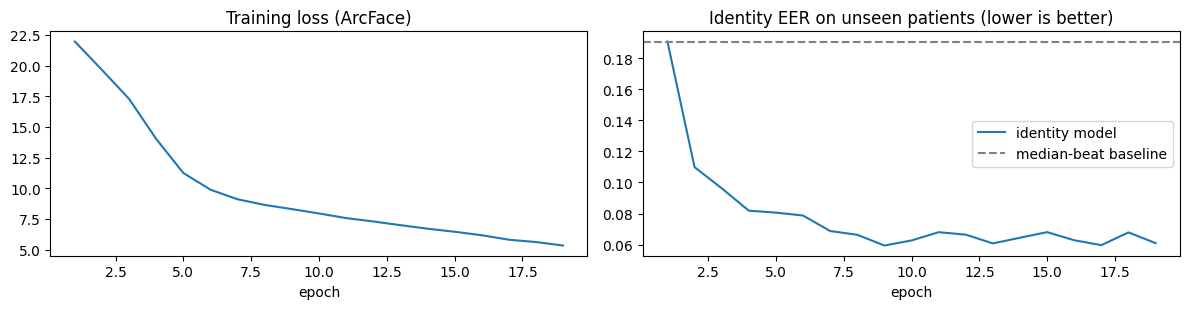

In [ ]:
import matplotlib.pyplot as plt
id_model, st = TR.load_best(CFG, MAIN_DIR, DEVICE)
final_id = EV.verification(EV.embed(id_model, idv["signal"], WINDOW, DEVICE), idv["patient_id"], idv["date"])
base_eer = gate2["identity_baseline"]["eer"]
IDENTITY_OK = final_id["eer"] <= PLAN["IDENTITY_MAX_RATIO"] * base_eer
print(f"Identity model (best epoch {st['epoch']}): EER {final_id['eer']:.3f} | rank-1 {final_id['rank1']:.3f}")
print(f"Median-beat baseline: EER {base_eer:.3f} | rank-1 {gate2['identity_baseline']['rank1']:.3f}")
print(f"Identity check (EER <= {PLAN['IDENTITY_MAX_RATIO']} x baseline = {PLAN['IDENTITY_MAX_RATIO'] * base_eer:.3f}):",
      "PASS" if IDENTITY_OK else "FAIL: fix the identity model before measuring any leak")

h = pd.read_csv(f"{MAIN_DIR}/history.csv")
fig, ax = plt.subplots(1, 2, figsize=(12, 3.2))
ax[0].plot(h["epoch"], h["loss"]); ax[0].set_title("Training loss (ArcFace)"); ax[0].set_xlabel("epoch")
ax[1].plot(h["epoch"], h["eer"], label="identity model"); ax[1].axhline(base_eer, ls="--", c="grey", label="median-beat baseline")
ax[1].set_title("Identity EER on unseen patients (lower is better)"); ax[1].set_xlabel("epoch"); ax[1].legend()
plt.tight_layout(); plt.savefig(f"{PATHS['figures']}/phase3_identity_training.png", dpi=150); plt.show()

Cell 3.4: Leak-measurement code (leakage.py)

What: functions to fit the attacker on probe-dev and score the lockbox once. It also adds the patient bootstrap, which gives confidence intervals, and the paired permutation test, which gives p-values.
Why: the statistics live in one module, so Phase 4 reuses exactly the same method for the other diseases.

In [ ]:
%%writefile /content/drive/MyDrive/ecg_leak/src/ecgleak/leakage.py
import warnings
import numpy as np
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegressionCV
from sklearn.metrics import roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
warnings.filterwarnings("ignore", category=FutureWarning, module="sklearn")

def fit_and_score(X_dev, y_dev, folds, X_test, C_grid, pca=None, seed=0):
    """Choose C by CV over the probe-dev patient folds, refit on all probe-dev, score the test set once."""
    cv = [(np.where(folds != f)[0], np.where(folds == f)[0]) for f in np.unique(folds)]
    steps = [StandardScaler()]
    if pca:
        steps.append(PCA(n_components=min(pca, X_dev.shape[1]), random_state=seed))
    steps.append(LogisticRegressionCV(Cs=list(C_grid), cv=cv, scoring="roc_auc", max_iter=5000))
    model = make_pipeline(*steps).fit(X_dev, y_dev)
    return model.predict_proba(X_test)[:, 1], float(model[-1].C_[0])

def auc(y, s):
    return float(roc_auc_score(y, s))

def paired_bootstrap(y, scores, n_boot=2000, seed=0):
    """scores: dict name -> test-set scores. Resamples patients (one record each) and recomputes every AUROC."""
    rng = np.random.default_rng(seed)
    n, out = len(y), {k: [] for k in scores}
    for _ in range(n_boot):
        i = rng.integers(0, n, n)
        if y[i].min() == y[i].max():
            continue
        for k, s in scores.items():
            out[k].append(roc_auc_score(y[i], s[i]))
    return {k: np.array(v) for k, v in out.items()}

def percentile_rank(s):
    return (np.argsort(np.argsort(s)) + 0.5) / len(s)

def paired_permutation(y, s_a, s_b, n_perm=1000, seed=0):
    """Two-sided p-value for AUROC(a) - AUROC(b): swap the two scores within each patient at random."""
    rng = np.random.default_rng(seed)
    a, b = percentile_rank(s_a), percentile_rank(s_b)
    obs = roc_auc_score(y, a) - roc_auc_score(y, b)
    null = np.empty(n_perm)
    for j in range(n_perm):
        swap = rng.random(len(y)) < 0.5
        null[j] = roc_auc_score(y, np.where(swap, b, a)) - roc_auc_score(y, np.where(swap, a, b))
    return float((1 + np.sum(np.abs(null) >= abs(obs))) / (n_perm + 1))

Writing /content/drive/MyDrive/ecg_leak/src/ecgleak/leakage.py


Cell 3.5: Freeze everything before opening the lockbox

What: refuses to continue if the identity check failed. Otherwise it records the exact model file (by fingerprint), the splits and the rules in gates/gate_3_ready.json.
Why: this is the “seal”. If anyone later tries to open the lockbox with a different, retrained model, the cell refuses. The paper’s result must come from the first frozen model.

In [ ]:
import ecgleak.leakage as LK
importlib.reload(LK)
pdv = D["probe_dev"]
keep_dev, y_dev = EV.task_data(pdv["labels"], SUPER, CFG["leakage"]["primary"])
folds_dev = pdv["fold"][keep_dev]

def file_sha(p):
    return hashlib.sha256(open(p, "rb").read()).hexdigest()

ready = {"plan": PLAN, "identity_ok": IDENTITY_OK, "identity_eer": final_id["eer"], "baseline_eer": base_eer,
         "model_file": f"{MAIN_DIR}/best.pt", "model_sha256": file_sha(f"{MAIN_DIR}/best.pt"),
         "best_epoch": st["epoch"], "splits_sha256": file_sha(f"{PATHS['splits']}/splits.csv"),
         "n_dev": int(keep_dev.sum()), "frozen_at": datetime.datetime.now().isoformat(timespec="seconds")}
assert IDENTITY_OK, "Identity check failed (cell 3.3): do NOT open the lockbox. Improve the identity model first."
ready_path = f"{PATHS['gates']}/gate_3_ready.json"
if os.path.isfile(ready_path):
    prev = json.load(open(ready_path))
    assert prev["model_sha256"] == ready["model_sha256"], \
        "A different model was frozen before. The lockbox result must come from the first frozen model."
    ready = prev
    print("Already frozen on", ready["frozen_at"], "(same model): continuing")
else:
    json.dump(ready, open(ready_path, "w"), indent=2, default=str)
    print("Frozen:", ready_path)
print(f"Model sha256 {ready['model_sha256'][:16]}... | best epoch {ready['best_epoch']} | probe-dev records for the task {ready['n_dev']:,}")

Frozen: /content/drive/MyDrive/ecg_leak/gates/gate_3_ready.json
Model sha256 ac96d7e85caecc9a... | best epoch 9 | probe-dev records for the task 7,863


Cell 3.6: Open the lockbox and score every representation (about 10–20 minutes)

What: loads the lockbox for the first time and builds 9 representations of each record:

the identity template;
5 untrained copies;
the raw median beat;
age + sex;
the template plus age + sex.

For each one it trains the attacker on probe-dev only, then scores the lockbox once. The scores are saved to Drive.
Why: every representation faces the same attacker on the same patients, so the differences between them are fair. These are the numbers the paper’s main result rests on.


In [ ]:
LOCK = load_split("lockbox")
keep_lb, y_lb = EV.task_data(LOCK["labels"], SUPER, CFG["leakage"]["primary"])
print(f"Lockbox opened: {PLAN['primary_task']} | positives {y_lb.sum():,} | NORM-only {(1 - y_lb).sum():,}")

def reps(d, keep):
    sig = d["signal"][keep]
    out = {"identity_template": EV.embed(id_model, sig, WINDOW, DEVICE)}
    for k, m in enumerate(M.untrained_copies(CFG, PLAN["untrained_seeds"], DEVICE)):
        out[f"untrained_{k}"] = EV.embed(m, sig, WINDOW, DEVICE)
    out["raw_median_beat"] = d["median_beat"][keep]
    out["age_sex"] = EV.demo_features(d["age"][keep], d["sex"][keep])
    out["template_plus_age_sex"] = np.c_[out["identity_template"], out["age_sex"]]
    return out

R_dev, R_lb = reps(pdv, keep_dev), reps(LOCK, keep_lb)
scores, chosen_C = {}, {}
for name in R_dev:
    scores[name], chosen_C[name] = LK.fit_and_score(R_dev[name], y_dev, folds_dev, R_lb[name], PLAN["C_grid"],
                                                    pca=64 if name == "raw_median_beat" else None)
aucs = {k: LK.auc(y_lb, s) for k, s in scores.items()}
np.savez(f"{PATHS['results']}/lockbox_scores_{CFG['leakage']['primary']}.npz", y=y_lb,
         ecg_id=LOCK["ecg_id"][keep_lb], **scores)
print(pd.Series(aucs, name="lockbox AUROC").round(4).to_string())

Lockbox opened: CD vs NORM | positives 1,072 | NORM-only 2,300
identity_template        0.8665
untrained_0              0.8352
untrained_1              0.8454
untrained_2              0.8349
untrained_3              0.8349
untrained_4              0.8400
raw_median_beat          0.8228
age_sex                  0.7576
template_plus_age_sex    0.8871


Cell 3.7: The three gains, with confidence intervals and p-values (about 2–5 minutes)

What: computes the three gains:

Δ_rand: the template versus the average of the 5 untrained copies;
Δ_raw: the template versus the raw heartbeat;
Δ_demo: template plus age + sex versus age + sex alone.

Each gets a 95% confidence interval from 2,000 patient-bootstrap resamples and a p-value from 1,000 permutations.
Why: a gain only counts if its interval sits clearly above zero. The interval shows how much the number could move with a different sample of patients.

In [ ]:
untr = [k for k in scores if k.startswith("untrained_")]
boot = LK.paired_bootstrap(y_lb, scores, PLAN["n_boot"], seed=CFG["seed"])
def ci(x):
    return float(np.percentile(x, 2.5)), float(np.percentile(x, 97.5))

d_rand_boot = boot["identity_template"] - np.mean([boot[k] for k in untr], axis=0)
deltas = {
    "Delta_rand": (aucs["identity_template"] - np.mean([aucs[k] for k in untr]), d_rand_boot),
    "Delta_raw": (aucs["identity_template"] - aucs["raw_median_beat"], boot["identity_template"] - boot["raw_median_beat"]),
    "Delta_demo": (aucs["template_plus_age_sex"] - aucs["age_sex"], boot["template_plus_age_sex"] - boot["age_sex"]),
}
pooled_untrained = np.mean([LK.percentile_rank(scores[k]) for k in untr], axis=0)
pvals = {"Delta_rand": LK.paired_permutation(y_lb, scores["identity_template"], pooled_untrained, PLAN["n_perm"], CFG["seed"]),
         "Delta_raw": LK.paired_permutation(y_lb, scores["identity_template"], scores["raw_median_beat"], PLAN["n_perm"], CFG["seed"]),
         "Delta_demo": LK.paired_permutation(y_lb, scores["template_plus_age_sex"], scores["age_sex"], PLAN["n_perm"], CFG["seed"])}
table = pd.DataFrame([{"gain": k, "estimate": v[0], "ci_low": ci(v[1])[0], "ci_high": ci(v[1])[1],
                       "ci_halfwidth": (ci(v[1])[1] - ci(v[1])[0]) / 2, "p_perm": pvals[k]}
                      for k, v in deltas.items()]).set_index("gain")
table.to_csv(f"{PATHS['results']}/main_leakage_{CFG['leakage']['primary']}.csv")
print(f"{PLAN['primary_task']} on the lockbox ({len(y_lb):,} patients), {len(d_rand_boot)} bootstrap resamples:\n")
print(table.round(4).to_string())

CD vs NORM on the lockbox (3,372 patients), 2000 bootstrap resamples:

            estimate  ci_low  ci_high  ci_halfwidth  p_perm
gain                                                       
Delta_rand    0.0284  0.0195   0.0379        0.0092   0.001
Delta_raw     0.0437  0.0291   0.0579        0.0144   0.001
Delta_demo    0.1295  0.1133   0.1455        0.0161   0.001


Cell 3.8: Figure 1

What: draws a forest plot: each gain as a dot with its confidence interval, and a dashed line at zero.
Why: this is the paper’s main figure. If a bar sits fully to the right of the dashed line, that gain is real.

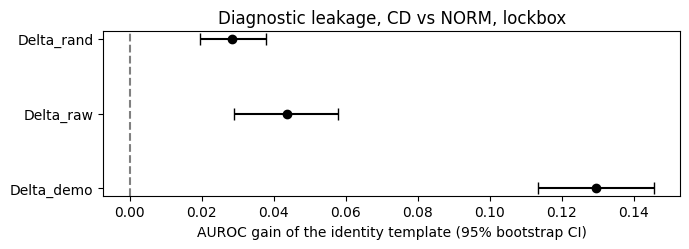

In [ ]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(7, 2.6))
yy = np.arange(len(table))[::-1]
ax.errorbar(table["estimate"], yy, xerr=[table["estimate"] - table["ci_low"], table["ci_high"] - table["estimate"]],
            fmt="o", capsize=4, color="black")
ax.axvline(0, color="grey", ls="--")
ax.set_yticks(yy); ax.set_yticklabels(table.index)
ax.set_xlabel("AUROC gain of the identity template (95% bootstrap CI)")
ax.set_title(f"Diagnostic leakage, {PLAN['primary_task']}, lockbox")
plt.tight_layout(); plt.savefig(f"{PATHS['figures']}/figure1_main_leakage_{CFG['leakage']['primary']}.png", dpi=200); plt.show()

Cell 3.9: Phase 3 gate and verdict on H1 and H2

What: applies the locked rules. It prints whether H1 (the template leaks CD beyond untrained copies) and H2 (also beyond the raw heartbeat and beyond age + sex) are supported, and whether the result is precise enough. Everything is saved to gates/gate_3.json.
Why: the verdict comes from rules written before the result, not from judgement afterwards. Both “supported” and “not supported” are publishable answers.

In [ ]:
row = table.to_dict("index")
excl0 = lambda k: row[k]["ci_low"] > 0
H1 = row["Delta_rand"]["estimate"] > 0 and excl0("Delta_rand")
H2 = row["Delta_raw"]["estimate"] > 0 and excl0("Delta_raw") and row["Delta_demo"]["estimate"] > 0 and excl0("Delta_demo")
PRECISE = row["Delta_rand"]["ci_halfwidth"] <= PLAN["ci_halfwidth_target"]
gate = {"Identity model beats baseline": IDENTITY_OK, "Settings frozen before lockbox": os.path.isfile(ready_path),
        "Lockbox scored once with frozen model": True,
        f"Delta_rand CI half-width <= {PLAN['ci_halfwidth_target']}": PRECISE}
print("PHASE 3 GATE\n" + "-" * 55)
for k, v in gate.items():
    print(f"  {'PASS' if v else 'FAIL'}  {k}")
print("-" * 55)
print(f"H1 (identity template leaks CD beyond untrained copies): {'SUPPORTED' if H1 else 'NOT SUPPORTED'}")
print(f"H2 (beyond raw heartbeat AND beyond age+sex):            {'SUPPORTED' if H2 else 'NOT SUPPORTED'}")
if not PRECISE:
    print("CI wider than the target: report the result as imprecise; do not add lockbox data or re-run with new settings.")
GO = gate["Identity model beats baseline"] and gate["Settings frozen before lockbox"]
json.dump({"phase": 3, "go": GO, "checks": gate, "H1_supported": H1, "H2_supported": H2, "precise": PRECISE,
           "identity": final_id, "aucs": aucs, "chosen_C": chosen_C, "gains": table.reset_index().to_dict("records"),
           "n_lockbox": int(len(y_lb)), "environment": ecfg.environment()},
          open(f"{PATHS['gates']}/gate_3.json", "w"), indent=2, default=str)
print("Saved gates/gate_3.json, results/main_leakage_*.csv and Figure 1.")

PHASE 3 GATE
-------------------------------------------------------
  PASS  Identity model beats baseline
  PASS  Settings frozen before lockbox
  PASS  Lockbox scored once with frozen model
  PASS  Delta_rand CI half-width <= 0.03
-------------------------------------------------------
H1 (identity template leaks CD beyond untrained copies): SUPPORTED
H2 (beyond raw heartbeat AND beyond age+sex):            SUPPORTED
Saved gates/gate_3.json, results/main_leakage_*.csv and Figure 1.


Cell 4.0: Start the session

What: connects Drive, loads the config, and checks that the identity model on Drive is exactly the one frozen in Phase 3 (by its fingerprint). It also loads all four data splits.
Why: every Phase 4 number must come from the same frozen model as the main result. The lockbox was opened in Phase 3, and these extra diseases were listed in the plan in advance, so using it here is allowed.

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

import os, sys, json, shutil, importlib, time, math, hashlib
from pathlib import Path
import numpy as np, pandas as pd, torch

PROJECT = Path("/content/drive/MyDrive/ecg_leak")
sys.path.insert(0, str(PROJECT / "src"))
import ecgleak.config as ecfg
importlib.reload(ecfg)
CFG = ecfg.load(str(PROJECT / "config.yaml"))
PATHS = CFG["paths"]
gate3 = json.load(open(f"{PATHS['gates']}/gate_3.json"))
ready = json.load(open(f"{PATHS['gates']}/gate_3_ready.json"))
PLAN = json.load(open(f"{PATHS['gates']}/phase3_plan.json"))
assert gate3["go"], "Phase 3 gate is not GO"
MAIN_DIR = f"{PATHS['runs']}/id_main_s0"
assert hashlib.sha256(open(f"{MAIN_DIR}/best.pt", "rb").read()).hexdigest() == ready["model_sha256"], \
    "The identity model on Drive is not the one frozen in Phase 3"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
WINDOW = int(CFG["preprocess"]["window_s"] * CFG["data"]["fs"])
OUT = f"{PATHS['results']}/phase4"
os.makedirs(OUT, exist_ok=True)

LOCAL_CACHE = "/content/cache"
os.makedirs(LOCAL_CACHE, exist_ok=True)
splits = pd.read_csv(f"{PATHS['splits']}/splits.csv", index_col="ecg_id")
def load_split(s):
    dst = f"{LOCAL_CACHE}/{s}.npz"
    if not os.path.isfile(dst):
        shutil.copyfile(f"{PATHS['cache']}/{s}.npz", dst)
    z = np.load(dst, allow_pickle=False)
    d = {k: z[k] for k in z.files}
    d["date"] = pd.to_datetime(splits.loc[d["ecg_id"], "recording_date"]).to_numpy()
    return d
D = {s: load_split(s) for s in ["id_train", "id_eval", "probe_dev", "lockbox"]}
SUPER = list(D["probe_dev"]["label_names"])
print("Phase 3: GO | frozen model verified | H1", "SUPPORTED" if gate3["H1_supported"] else "NOT SUPPORTED",
      "| Device:", DEVICE)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Root /content/drive/MyDrive/ecg_leak | raw data /content/drive/MyDrive/PTB-XL | seed 0 | Python 3.13.16 | torch 2.11.0+cu130 | GPU Tesla T4
Phase 3: GO | frozen model verified | H1 SUPPORTED | Device: cuda


Cell 4.1: Updated training code (train.py)

What: the same training loop as before, with three additions:

a contrastive (Siamese) loss for the BiomECG-style model;
snapshots at chosen epochs for the H3 analysis;
a small diagnosis model, used only for the H4 attribution check.

Why: one shared training function keeps every model comparable. Your existing runs (id_main_s0, pilot_s0) still load unchanged.

In [ ]:
%%writefile /content/drive/MyDrive/ecg_leak/src/ecgleak/train.py
import glob, math, os, time
import numpy as np, torch, torch.nn as nn, torch.nn.functional as F
from .models import build_encoder, ArcFaceHead

def _schedule(opt, total, warm):
    def f(step):
        if step < warm:
            return (step + 1) / max(1, warm)
        return 0.5 * (1 + math.cos(math.pi * min(1.0, (step - warm) / max(1, total - warm))))
    return torch.optim.lr_scheduler.LambdaLR(opt, f)

def latest_checkpoint(run_dir):
    files = sorted(glob.glob(os.path.join(run_dir, "checkpoints", "epoch_*.pt")))
    return files[-1] if files else None

def _crops(signals, idx, offs, scale, window, rng):
    xb = np.stack([signals[i, o:o + window] for i, o in zip(idx, offs)]).astype(np.float32)
    return (xb * scale[:, None] + rng.normal(0, 0.05, xb.shape)).astype(np.float32)

def train_identity(cfg, signals, patient_ids, run_dir, device, epochs=None, eval_fn=None, crops_per_record=4,
                   seed=None, stop_after=None, max_steps_per_epoch=None, log=print, loss="arcface",
                   patience=None, snapshot_epochs=(), margin=0.3):
    """Identity training (ArcFace, or a Siamese contrastive loss) with automatic resume from run_dir."""
    t, seed = cfg["train"], cfg["seed"] if seed is None else seed
    epochs, patience = epochs or t["epochs"], patience or t["patience"]
    window = int(cfg["preprocess"]["window_s"] * cfg["data"]["fs"])
    classes, y_all = np.unique(patient_ids, return_inverse=True)
    members = [np.where(y_all == c)[0] for c in range(len(classes))]
    n, L, B = len(signals), signals.shape[1], t["batch"]
    steps = math.ceil(n * crops_per_record / B)
    if max_steps_per_epoch:
        steps = min(steps, max_steps_per_epoch)

    torch.manual_seed(seed)
    model = build_encoder(cfg).to(device)
    head = ArcFaceHead(cfg["model"]["emb_dim"], len(classes), cfg["arcface"]["s"], cfg["arcface"]["m"]).to(device) \
        if loss == "arcface" else None
    params = list(model.parameters()) + (list(head.parameters()) if head is not None else [])
    opt = torch.optim.AdamW(params, lr=t["lr"], weight_decay=t["weight_decay"])
    sched = _schedule(opt, steps * epochs, int(t["warmup_frac"] * steps * epochs))
    scaler = torch.amp.GradScaler("cuda", enabled=(device == "cuda"))
    os.makedirs(os.path.join(run_dir, "checkpoints"), exist_ok=True)
    os.makedirs(os.path.join(run_dir, "snapshots"), exist_ok=True)

    start, history, best, bad = 0, [], float("inf"), 0
    ck = latest_checkpoint(run_dir)
    if ck:
        st = torch.load(ck, map_location=device, weights_only=False)
        model.load_state_dict(st["model"])
        if head is not None:
            head.load_state_dict(st["head"])
        opt.load_state_dict(st["opt"]); sched.load_state_dict(st["sched"]); scaler.load_state_dict(st["scaler"])
        torch.set_rng_state(st["torch_rng"].cpu())
        if device == "cuda" and st.get("cuda_rng") is not None:
            torch.cuda.set_rng_state_all([s.cpu() for s in st["cuda_rng"]])
        start, history, best, bad = st["epoch"] + 1, st["history"], st["best"], st["bad"]
        log(f"Resumed from {os.path.basename(ck)} -> continuing at epoch {start + 1}")
        if bad >= patience or (stop_after is not None and start >= stop_after):
            log("This run had already finished.")
            return model, history

    for epoch in range(start, epochs):
        t0 = time.time()
        model.train()
        if head is not None:
            head.train()
        rng = np.random.default_rng(seed * 1000 + epoch)
        idx = np.repeat(np.arange(n), crops_per_record); rng.shuffle(idx)
        tot_loss = tot_acc = 0.0
        for b in range(steps):
            ii = idx[b * B:(b + 1) * B]
            m = len(ii)
            if loss == "arcface":
                xb = _crops(signals, ii, rng.integers(0, L - window + 1, m), rng.uniform(0.9, 1.1, m), window, rng)
                yb = torch.from_numpy(y_all[ii]).long().to(device)
                with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=(device == "cuda")):
                    emb = model(torch.from_numpy(xb).to(device))
                logits = head(emb.float(), yb)
                L_b = F.cross_entropy(logits, yb)
                acc = (logits.argmax(1) == yb).float().mean().item()
            else:
                pos = np.array([rng.choice(members[y_all[i]][members[y_all[i]] != i])
                                if len(members[y_all[i]]) > 1 else i for i in ii])
                neg = rng.integers(0, n, m)
                clash = y_all[neg] == y_all[ii]
                while clash.any():
                    neg[clash] = rng.integers(0, n, clash.sum()); clash = y_all[neg] == y_all[ii]
                allx = np.concatenate([_crops(signals, j, rng.integers(0, L - window + 1, m), rng.uniform(0.9, 1.1, m), window, rng)
                                       for j in (ii, pos, neg)])
                with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=(device == "cuda")):
                    e = model(torch.from_numpy(allx).to(device)).float()
                a, p, q = e[:m], e[m:2 * m], e[2 * m:]
                cap, can = (a * p).sum(1), (a * q).sum(1)
                L_b = ((1 - cap) ** 2).mean() + (F.relu(can - margin) ** 2).mean()
                acc = (cap > can).float().mean().item()
            opt.zero_grad(set_to_none=True)
            scaler.scale(L_b).backward()
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(params, 5.0)
            scaler.step(opt); scaler.update(); sched.step()
            tot_loss += L_b.item(); tot_acc += acc
        rec = {"epoch": epoch + 1, "loss": tot_loss / steps, "train_acc": tot_acc / steps,
               "lr": sched.get_last_lr()[0], "seconds": round(time.time() - t0, 1)}
        if eval_fn is not None:
            rec.update(eval_fn(model))
        if rec.get("eer", -epoch) < best:
            best, bad = rec.get("eer", -epoch), 0
            torch.save({"model": model.state_dict(), "epoch": epoch + 1, "eer": rec.get("eer")},
                       os.path.join(run_dir, "best.pt"))
        else:
            bad += 1
        if epoch + 1 in snapshot_epochs:
            torch.save({"model": model.state_dict(), "epoch": epoch + 1, "eer": rec.get("eer")},
                       os.path.join(run_dir, "snapshots", f"epoch_{epoch + 1:03d}.pt"))
        history.append(rec)
        path = os.path.join(run_dir, "checkpoints", f"epoch_{epoch + 1:03d}.pt")
        torch.save({"epoch": epoch, "model": model.state_dict(), "head": head.state_dict() if head is not None else None,
                    "opt": opt.state_dict(), "sched": sched.state_dict(), "scaler": scaler.state_dict(),
                    "history": history, "best": best, "bad": bad, "torch_rng": torch.get_rng_state(),
                    "cuda_rng": torch.cuda.get_rng_state_all() if device == "cuda" else None}, path + ".tmp")
        os.replace(path + ".tmp", path)
        for old in sorted(glob.glob(os.path.join(run_dir, "checkpoints", "epoch_*.pt")))[:-3]:
            os.remove(old)
        log(" | ".join(f"{k} {v:.4f}" if isinstance(v, float) else f"{k} {v}" for k, v in rec.items()))
        if stop_after is not None and epoch + 1 >= stop_after:
            break
        if bad >= patience:
            log("Early stopping: identity EER stopped improving")
            break
    return model, history

def load_best(cfg, run_dir, device, name="best.pt"):
    model = build_encoder(cfg).to(device)
    st = torch.load(os.path.join(run_dir, name), map_location=device, weights_only=False)
    model.load_state_dict(st["model"])
    return model.eval(), st

class DiagNet(nn.Module):
    """Same encoder + one linear output: a supervised diagnosis model (used only for attributions, H4)."""
    def __init__(self, encoder):
        super().__init__()
        self.encoder, self.out = encoder, nn.Linear(encoder.emb_dim, 1)
    def forward(self, x):
        return self.out(self.encoder(x)).squeeze(1)

def train_diagnosis(cfg, signals, y, path, device, epochs=15, seed=0, log=print):
    window = int(cfg["preprocess"]["window_s"] * cfg["data"]["fs"])
    torch.manual_seed(seed)
    net = DiagNet(build_encoder(cfg)).to(device)
    if os.path.isfile(path):
        net.load_state_dict(torch.load(path, map_location=device, weights_only=False))
        log(f"Loaded existing {os.path.basename(path)}")
        return net.eval()
    opt = torch.optim.AdamW(net.parameters(), lr=1e-3, weight_decay=1e-4)
    pw = torch.tensor([(1 - y).sum() / max(1, y.sum())], device=device, dtype=torch.float32)
    n, L, B = len(signals), signals.shape[1], cfg["train"]["batch"]
    for epoch in range(epochs):
        net.train()
        rng = np.random.default_rng(seed * 1000 + epoch)
        idx = np.repeat(np.arange(n), 2); rng.shuffle(idx)
        tot = 0.0
        for b in range(math.ceil(len(idx) / B)):
            ii = idx[b * B:(b + 1) * B]
            xb = _crops(signals, ii, rng.integers(0, L - window + 1, len(ii)), rng.uniform(0.9, 1.1, len(ii)), window, rng)
            logit = net(torch.from_numpy(xb).to(device))
            l = F.binary_cross_entropy_with_logits(logit, torch.from_numpy(y[ii]).float().to(device), pos_weight=pw)
            opt.zero_grad(set_to_none=True); l.backward(); opt.step(); tot += l.item()
        log(f"  diag epoch {epoch + 1}: loss {tot / math.ceil(len(idx) / B):.4f}")
    torch.save(net.state_dict(), path)
    return net.eval()

Overwriting /content/drive/MyDrive/ecg_leak/src/ecgleak/train.py


Cell 4.2: Analysis code (analysis.py)

What:

two stronger attackers: a small neural network (MLP) and nearest-neighbours (kNN);
the three-gains calculation from Phase 3, as a reusable function;
Benjamini–Hochberg correction for testing four diseases at once;
integrated-gradients attributions, and the repaired overlap measure: rank correlation on raw values, with no min–max offset.

Why: reusing the same statistics as Phase 3 keeps every number comparable. The overlap measure fixes the HPOS problems you found earlier.

In [ ]:
%%writefile /content/drive/MyDrive/ecg_leak/src/ecgleak/analysis.py
import warnings
import numpy as np, pandas as pd, torch, torch.nn.functional as F
from scipy.stats import spearmanr
from sklearn.model_selection import GridSearchCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from . import leakage as LK
warnings.filterwarnings("ignore", category=FutureWarning, module="sklearn")

def fit_and_score(X_dev, y_dev, folds, X_test, C_grid, attacker="logreg", pca=None, seed=0):
    """Same protocol as Phase 3, with a choice of attacker."""
    if attacker == "logreg":
        return LK.fit_and_score(X_dev, y_dev, folds, X_test, C_grid, pca=pca, seed=seed)[0]
    cv = [(np.where(folds != f)[0], np.where(folds == f)[0]) for f in np.unique(folds)]
    if attacker == "mlp":
        model = make_pipeline(StandardScaler(), MLPClassifier((256,), alpha=1e-3, early_stopping=True,
                                                              max_iter=300, random_state=seed))
        model.fit(X_dev, y_dev)
    elif attacker == "knn":
        model = GridSearchCV(make_pipeline(StandardScaler(), KNeighborsClassifier(weights="distance")),
                             {"kneighborsclassifier__n_neighbors": [5, 15, 31, 63]}, cv=cv, scoring="roc_auc")
        model.fit(X_dev, y_dev)
    else:
        raise ValueError(attacker)
    return model.predict_proba(X_test)[:, 1]

def gains(y, scores, n_boot, n_perm, seed=0):
    """Delta_rand / Delta_raw / Delta_demo with paired-bootstrap 95% CIs and permutation p-values (as Phase 3)."""
    aucs = {k: LK.auc(y, s) for k, s in scores.items()}
    boot = LK.paired_bootstrap(y, scores, n_boot, seed)
    untr = [k for k in scores if k.startswith("untrained_")]
    rows = []
    def add(name, est, b, a, bb):
        lo, hi = np.percentile(b, [2.5, 97.5])
        rows.append({"gain": name, "estimate": est, "ci_low": lo, "ci_high": hi, "ci_halfwidth": (hi - lo) / 2,
                     "p_perm": LK.paired_permutation(y, a, bb, n_perm, seed)})
    pooled = np.mean([LK.percentile_rank(scores[k]) for k in untr], axis=0)
    add("Delta_rand", aucs["identity_template"] - np.mean([aucs[k] for k in untr]),
        boot["identity_template"] - np.mean([boot[k] for k in untr], axis=0), scores["identity_template"], pooled)
    if "raw_median_beat" in scores:
        add("Delta_raw", aucs["identity_template"] - aucs["raw_median_beat"],
            boot["identity_template"] - boot["raw_median_beat"], scores["identity_template"], scores["raw_median_beat"])
    if "age_sex" in scores:
        add("Delta_demo", aucs["template_plus_age_sex"] - aucs["age_sex"],
            boot["template_plus_age_sex"] - boot["age_sex"], scores["template_plus_age_sex"], scores["age_sex"])
    return pd.DataFrame(rows).set_index("gain"), aucs

def bh(p):
    """Benjamini-Hochberg adjusted p-values."""
    p = np.asarray(p, dtype=float); n = len(p); o = np.argsort(p)
    q = p[o] * n / np.arange(1, n + 1)
    q = np.minimum.accumulate(q[::-1])[::-1]
    out = np.empty(n); out[o] = np.minimum(q, 1)
    return out

def integrated_gradients(f, x, steps=32):
    """IG from a zero baseline; f maps a batch of windows to one number per window."""
    total = torch.zeros_like(x)
    for a in torch.linspace(1.0 / steps, 1.0, steps, device=x.device):
        xi = (a * x).detach().requires_grad_(True)
        g, = torch.autograd.grad(f(xi).sum(), xi)
        total += g
    return (x * total / steps).detach()

def identity_score_fn(model, x_full_windows):
    """Output to explain for an identity encoder: similarity of window 1 to the record's own template."""
    with torch.no_grad():
        ref = F.normalize(model(x_full_windows.reshape(-1, x_full_windows.shape[-1]))
                          .reshape(x_full_windows.shape[0], x_full_windows.shape[1], -1).mean(1), dim=1)
    return lambda xi: (model(xi) * ref).sum(1)

def overlap(a, b):
    """Per-record Spearman rank correlation of |attribution| over time (raw values, no min-max offset)."""
    return np.array([spearmanr(np.abs(u), np.abs(v))[0] for u, v in zip(a, b)])

Writing /content/drive/MyDrive/ecg_leak/src/ecgleak/analysis.py


Cell 4.3: Build every representation once (about 2–3 minutes)

What: loads the frozen identity model and the 5 untrained copies, then computes every representation for all probe-dev and lockbox records: templates, untrained embeddings, raw beat, and age + sex. It also defines run_task, which runs one disease with one attacker.
Why: computing everything once saves GPU time, and every later cell reads the same numbers.

In [ ]:
import ecgleak.models as M, ecgleak.train as TR, ecgleak.evaluate as EV, ecgleak.leakage as LK, ecgleak.analysis as AN
for mod in (M, TR, EV, LK, AN):
    importlib.reload(mod)
id_model, _ = TR.load_best(CFG, MAIN_DIR, DEVICE)
UNTRAINED = M.untrained_copies(CFG, PLAN["untrained_seeds"], DEVICE)

def all_reps(d, enc=None):
    enc = enc or id_model
    r = {"identity_template": EV.embed(enc, d["signal"], WINDOW, DEVICE)}
    for k, m in enumerate(UNTRAINED):
        r[f"untrained_{k}"] = EV.embed(m, d["signal"], WINDOW, DEVICE)
    r["raw_median_beat"] = d["median_beat"]
    r["age_sex"] = EV.demo_features(d["age"], d["sex"])
    r["template_plus_age_sex"] = np.c_[r["identity_template"], r["age_sex"]]
    return r
REP = {s: all_reps(D[s]) for s in ["probe_dev", "lockbox"]}
pdv, idv = D["probe_dev"], D["id_eval"]
def id_eval_fn(model):
    r = EV.verification(EV.embed(model, idv["signal"], WINDOW, DEVICE), idv["patient_id"], idv["date"])
    return {"eer": r["eer"], "rank1": r["rank1"]}
print("Representations ready:", list(REP["lockbox"]))

def run_task(cls, reps=REP, names=None, attacker="logreg"):
    keep_d, y_d = EV.task_data(D["probe_dev"]["labels"], SUPER, cls)
    keep_l, y_l = EV.task_data(D["lockbox"]["labels"], SUPER, cls)
    folds = D["probe_dev"]["fold"][keep_d]
    names = names or list(reps["lockbox"])
    sc = {k: AN.fit_and_score(reps["probe_dev"][k][keep_d], y_d, folds, reps["lockbox"][k][keep_l], PLAN["C_grid"],
                              attacker=attacker, pca=64 if k == "raw_median_beat" else None, seed=CFG["seed"])
          for k in names}
    return y_l, sc

Representations ready: ['identity_template', 'untrained_0', 'untrained_1', 'untrained_2', 'untrained_3', 'untrained_4', 'raw_median_beat', 'age_sex', 'template_plus_age_sex']


Cell 4.4: All four diseases, with multiple-testing correction (about 15–25 minutes)

What: repeats the Phase 3 measurement for CD, MI, STTC and HYP against normal, then corrects the p-values for testing four diseases (Benjamini–Hochberg). It also checks that CD reproduces the Phase 3 number exactly.
Why: the paper’s Table 3 shows which diseases leak. The CD check proves this cell uses the same pipeline as the main result.

In [ ]:
tables, auc_rows = [], []
for cls in CFG["leakage"]["tasks"]:
    y_l, sc = run_task(cls)
    if y_l.sum() < 30 or (1 - y_l).sum() < 30:
        print(f"{cls}: too few lockbox records, skipped"); continue
    tab, aucs = AN.gains(y_l, sc, PLAN["n_boot"], PLAN["n_perm"], CFG["seed"])
    tables.append(tab.assign(task=f"{cls} vs NORM", n_pos=int(y_l.sum()), n_neg=int((1 - y_l).sum())).reset_index())
    auc_rows.append({"task": f"{cls} vs NORM", **aucs})
    print(f"{cls} done")
sec = pd.concat(tables, ignore_index=True)
sec["p_BH"] = np.nan
for g, idx in sec.groupby("gain").groups.items():
    sec.loc[idx, "p_BH"] = AN.bh(sec.loc[idx, "p_perm"])
sec = sec[["task", "gain", "estimate", "ci_low", "ci_high", "p_perm", "p_BH", "n_pos", "n_neg"]]
sec.to_csv(f"{OUT}/table3_all_tasks.csv", index=False)
pd.DataFrame(auc_rows).to_csv(f"{OUT}/aucs_all_tasks.csv", index=False)
print(sec.round(4).to_string(index=False))
cd = sec[(sec.task.str.startswith(CFG["leakage"]["primary"] + " ")) & (sec.gain == "Delta_rand")]["estimate"]
p3 = [g["estimate"] for g in gate3["gains"] if g["gain"] == "Delta_rand"][0]
CONSISTENT = len(cd) == 1 and abs(cd.iloc[0] - p3) < 1e-3
print(f"\nConsistency check: CD Delta_rand here {cd.iloc[0]:+.4f} vs Phase 3 {p3:+.4f} ->", "PASS" if CONSISTENT else "FAIL")

CD done
MI done
STTC done
HYP done
        task       gain  estimate  ci_low  ci_high  p_perm   p_BH  n_pos  n_neg
  CD vs NORM Delta_rand    0.0284  0.0195   0.0379  0.0010 0.0020   1072   2300
  CD vs NORM  Delta_raw    0.0437  0.0291   0.0579  0.0010 0.0020   1072   2300
  CD vs NORM Delta_demo    0.1295  0.1133   0.1455  0.0010 0.0010   1072   2300
  MI vs NORM Delta_rand    0.0169  0.0100   0.0243  0.0110 0.0147   1124   2300
  MI vs NORM  Delta_raw    0.0219  0.0118   0.0327  0.0010 0.0020   1124   2300
  MI vs NORM Delta_demo    0.1218  0.1076   0.1369  0.0010 0.0010   1124   2300
STTC vs NORM Delta_rand    0.0128  0.0081   0.0173  0.0010 0.0020   1102   2300
STTC vs NORM  Delta_raw    0.0026 -0.0031   0.0081  0.3626 0.3626   1102   2300
STTC vs NORM Delta_demo    0.1904  0.1744   0.2067  0.0010 0.0010   1102   2300
 HYP vs NORM Delta_rand    0.0164  0.0075   0.0258  0.0170 0.0170    583   2300
 HYP vs NORM  Delta_raw    0.0198  0.0068   0.0328  0.0050 0.0067    583   2300
 HYP 

Cell 4.5: H5: do diagnoses that persist across visits leak more?

What: puts each disease’s persistence (from Phase 1: how often it’s still present at the next visit) next to its Δ_rand, computes a rank correlation, and draws Figure 2.
Why: a template is built to stay stable for one person over time. If it leaks the diseases that also stay stable, that explains why it leaks. With only 4 diseases, this is reported as a pattern, not a formal test.

      estimate  ci_low  ci_high  persistence  visit-1 positives
MI       0.017   0.010    0.024        0.766               1001
CD       0.028   0.020    0.038        0.723                787
STTC     0.013   0.008    0.017        0.671                910
HYP      0.016   0.008    0.026        0.615                408

Spearman rho (persistence vs Delta_rand) = +0.60 over 4 diagnoses (p = 0.40); with 4 points this is descriptive only.


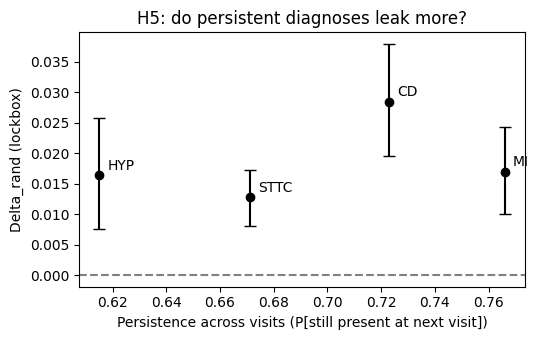

In [ ]:
from scipy.stats import spearmanr
persist = pd.read_csv(f"{PATHS['interim']}/persistence.csv", index_col=0)
dr = sec[sec.gain == "Delta_rand"].assign(cls=lambda t: t.task.str.split(" ").str[0]).set_index("cls")
h5 = dr[["estimate", "ci_low", "ci_high"]].join(persist[["persistence", "visit-1 positives"]], how="inner")
h5 = h5.sort_values("persistence", ascending=False)
rho, p = spearmanr(h5["persistence"], h5["estimate"]) if len(h5) >= 3 else (np.nan, np.nan)
h5.to_csv(f"{OUT}/h5_persistence_vs_leak.csv")
print(h5.round(3).to_string())
print(f"\nSpearman rho (persistence vs Delta_rand) = {rho:+.2f} over {len(h5)} diagnoses (p = {p:.2f}); "
      "with 4 points this is descriptive only.")

import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(5.5, 3.5))
ax.errorbar(h5["persistence"], h5["estimate"], yerr=[h5["estimate"] - h5["ci_low"], h5["ci_high"] - h5["estimate"]],
            fmt="o", capsize=4, color="black")
for c, r in h5.iterrows():
    ax.annotate(c, (r["persistence"], r["estimate"]), xytext=(6, 4), textcoords="offset points")
ax.axhline(0, ls="--", c="grey"); ax.set_xlabel("Persistence across visits (P[still present at next visit])")
ax.set_ylabel("Delta_rand (lockbox)"); ax.set_title("H5: do persistent diagnoses leak more?")
plt.tight_layout(); plt.savefig(f"{PATHS['figures']}/figure2_persistence_vs_leak.png", dpi=200); plt.show()

Cell 4.6: Stronger attackers (about 10 minutes)

What: repeats the CD Δ_rand measurement with two stronger attackers, a small neural network (MLP) and nearest-neighbours (kNN), alongside the original logistic regression.
Why: a reviewer will ask whether a smarter attacker finds more. If Δ_rand grows, the logistic number was a lower bound. If it stays about the same, the leak is robust to the attacker you choose.

In [ ]:
att_rows = []
names = ["identity_template"] + [f"untrained_{k}" for k in range(len(UNTRAINED))]
for attacker in ["logreg", "mlp", "knn"]:
    y_l, sc = run_task(CFG["leakage"]["primary"], names=names, attacker=attacker)
    tab, aucs = AN.gains(y_l, sc, PLAN["n_boot"], PLAN["n_perm"], CFG["seed"])
    r = tab.loc["Delta_rand"]
    att_rows.append({"attacker": attacker, "auroc_template": aucs["identity_template"],
                     "auroc_untrained_mean": np.mean([aucs[k] for k in names[1:]]),
                     "Delta_rand": r["estimate"], "ci_low": r["ci_low"], "ci_high": r["ci_high"], "p_perm": r["p_perm"]})
    print(f"{attacker} done")
att = pd.DataFrame(att_rows).set_index("attacker")
att.to_csv(f"{OUT}/attackers_{CFG['leakage']['primary']}.csv")
print(att.round(4).to_string())

logreg done
mlp done
knn done
          auroc_template  auroc_untrained_mean  Delta_rand  ci_low  ci_high  p_perm
attacker                                                                           
logreg            0.8665                0.8381      0.0284  0.0195   0.0379  0.0010
mlp               0.8550                0.8425      0.0125  0.0025   0.0229  0.1918
knn               0.8542                0.8078      0.0464  0.0341   0.0578  0.0010


Cell 4.7: H3: does a better biometric leak more? (about 10–15 minutes)

What: re-trains the identity model along the same 19-epoch path as your main run, saving snapshots at epochs 1, 2, 3, 4, 5, 6, 8, 10, 12, 15 and 19. For each snapshot it measures identity EER and Δ_rand on probe-dev only, so the lockbox isn’t used again, then draws Figure 3.
Why: if leakage rises as identity accuracy improves, privacy and utility are tied together. That would mean you can’t make a better biometric without making it leak more.

epoch 1 | loss 21.9500 | train_acc 0.0000 | lr 0.0003 | seconds 4.4000 | eer 0.1888 | rank1 0.2378
epoch 2 | loss 19.5978 | train_acc 0.0000 | lr 0.0007 | seconds 4.1000 | eer 0.1171 | rank1 0.4528
epoch 3 | loss 17.1996 | train_acc 0.0001 | lr 0.0010 | seconds 4.2000 | eer 0.0962 | rank1 0.5280
epoch 4 | loss 13.9920 | train_acc 0.0020 | lr 0.0010 | seconds 4.2000 | eer 0.0818 | rank1 0.5542
epoch 5 | loss 11.2868 | train_acc 0.0068 | lr 0.0010 | seconds 4.2000 | eer 0.0781 | rank1 0.5787
epoch 6 | loss 9.7900 | train_acc 0.0146 | lr 0.0010 | seconds 4.3000 | eer 0.0665 | rank1 0.6101
epoch 7 | loss 9.0550 | train_acc 0.0215 | lr 0.0010 | seconds 4.3000 | eer 0.0734 | rank1 0.6171
epoch 8 | loss 8.5339 | train_acc 0.0352 | lr 0.0010 | seconds 4.2000 | eer 0.0701 | rank1 0.6241
epoch 9 | loss 8.2424 | train_acc 0.0413 | lr 0.0010 | seconds 4.2000 | eer 0.0611 | rank1 0.6346
epoch 10 | loss 7.7969 | train_acc 0.0549 | lr 0.0010 | seconds 4.2000 | eer 0.0581 | rank1 0.6696
epoch 11 | los

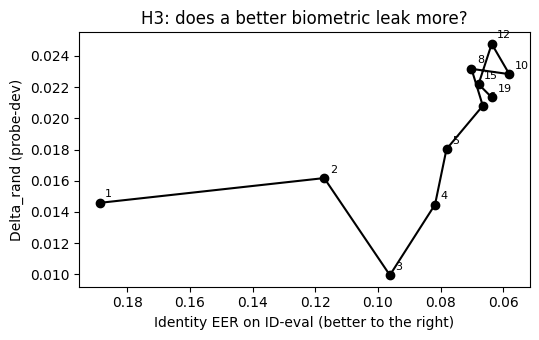

In [ ]:
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
COUP_DIR = f"{PATHS['runs']}/coupling_s0"
main_epochs = len(pd.read_csv(f"{MAIN_DIR}/history.csv"))          # 19 in your main run
SNAPS = tuple(sorted({1, 2, 3, 4, 5, 6, 8, 10, 12, 15, main_epochs} & set(range(1, main_epochs + 1))))
ecfg.freeze(CFG, COUP_DIR)
TR.train_identity(CFG, D["id_train"]["signal"], D["id_train"]["patient_id"], COUP_DIR, DEVICE,
                  stop_after=main_epochs, eval_fn=id_eval_fn, patience=10 ** 6, snapshot_epochs=SNAPS)

keep, y = EV.task_data(pdv["labels"], SUPER, CFG["leakage"]["primary"])
folds, sig = pdv["fold"][keep], pdv["signal"][keep]
rand_dev = np.mean([EV.cv_auroc(REP["probe_dev"][f"untrained_{k}"][keep], y, folds, PLAN["C_grid"])[0]
                    for k in range(len(UNTRAINED))])
rows = []
for f in sorted(os.listdir(f"{COUP_DIR}/snapshots")):
    m, st = TR.load_best(CFG, COUP_DIR, DEVICE, name=f"snapshots/{f}")
    a = EV.cv_auroc(EV.embed(m, sig, WINDOW, DEVICE), y, folds, PLAN["C_grid"])[0]
    rows.append({"epoch": st["epoch"], "eer": st["eer"], "auroc_dev": a, "Delta_rand_dev": a - rand_dev})
    print(f"epoch {st['epoch']:3d}: EER {st['eer']:.3f} | Delta_rand (probe-dev) {a - rand_dev:+.3f}")
coup = pd.DataFrame(rows)
coup.to_csv(f"{OUT}/h3_coupling.csv", index=False)
rho3, p3c = spearmanr(coup["eer"], coup["Delta_rand_dev"])
print(f"\nH3: Spearman rho(EER, Delta_rand) = {rho3:+.2f} (p = {p3c:.3f}) over {len(coup)} checkpoints. "
      "Negative = a better biometric (lower EER) leaks more.")
fig, ax = plt.subplots(figsize=(5.5, 3.5))
ax.plot(coup["eer"], coup["Delta_rand_dev"], "o-", color="black")
for _, r in coup.iterrows():
    ax.annotate(int(r["epoch"]), (r["eer"], r["Delta_rand_dev"]), xytext=(4, 4), textcoords="offset points", fontsize=8)
ax.invert_xaxis(); ax.set_xlabel("Identity EER on ID-eval (better to the right)"); ax.set_ylabel("Delta_rand (probe-dev)")
ax.set_title("H3: does a better biometric leak more?")
plt.tight_layout(); plt.savefig(f"{PATHS['figures']}/figure3_coupling.png", dpi=200); plt.show()

Cell 4.8: BiomECG-style Siamese comparator (about 5–10 minutes)

What: trains the same encoder with a contrastive (Siamese) loss instead of ArcFace: same-person pairs are pulled together, different-person pairs pushed apart. It then measures its identity EER and its CD Δ_rand, and compares both with the main ArcFace model.
Why: BiomECG (2026) is your closest prior work and uses a Siamese biometric. If this design also leaks, the leak is a property of ECG biometrics in general, not of one training trick. That strengthens the paper’s claim.

In [ ]:
SIAM_DIR = f"{PATHS['runs']}/siamese_s0"
ecfg.freeze(CFG, SIAM_DIR)
TR.train_identity(CFG, D["id_train"]["signal"], D["id_train"]["patient_id"], SIAM_DIR, DEVICE,
                  eval_fn=id_eval_fn, loss="contrastive")
siam, st_s = TR.load_best(CFG, SIAM_DIR, DEVICE)
siam_id = EV.verification(EV.embed(siam, idv["signal"], WINDOW, DEVICE), idv["patient_id"], idv["date"])
names = ["identity_template"] + [f"untrained_{k}" for k in range(len(UNTRAINED))]
REP_S = {s: {**{k: REP[s][k] for k in names[1:]}, "identity_template": EV.embed(siam, D[s]["signal"], WINDOW, DEVICE)}
         for s in ["probe_dev", "lockbox"]}
y_l, sc = run_task(CFG["leakage"]["primary"], reps=REP_S, names=names)
tab_s, aucs_s = AN.gains(y_l, sc, PLAN["n_boot"], PLAN["n_perm"], CFG["seed"])
arc = [g for g in gate3["gains"] if g["gain"] == "Delta_rand"][0]
comp = pd.DataFrame([
    {"model": "ArcFace (main)", "eer": gate3["identity"]["eer"], "rank1": gate3["identity"]["rank1"],
     "Delta_rand": arc["estimate"], "ci_low": arc["ci_low"], "ci_high": arc["ci_high"]},
    {"model": "Siamese contrastive (BiomECG-style)", "eer": siam_id["eer"], "rank1": siam_id["rank1"],
     "Delta_rand": tab_s.loc["Delta_rand", "estimate"], "ci_low": tab_s.loc["Delta_rand", "ci_low"],
     "ci_high": tab_s.loc["Delta_rand", "ci_high"]}]).set_index("model")
comp.to_csv(f"{OUT}/siamese_vs_arcface.csv")
print(comp.round(4).to_string())

epoch 1 | loss 0.1369 | train_acc 0.9063 | lr 0.0003 | seconds 15.1000 | eer 0.1170 | rank1 0.4003
epoch 2 | loss 0.0816 | train_acc 0.9617 | lr 0.0007 | seconds 14.6000 | eer 0.1030 | rank1 0.4510
epoch 3 | loss 0.0747 | train_acc 0.9679 | lr 0.0010 | seconds 12.4000 | eer 0.0962 | rank1 0.4563
epoch 4 | loss 0.0692 | train_acc 0.9734 | lr 0.0010 | seconds 12.3000 | eer 0.0971 | rank1 0.4843
epoch 5 | loss 0.0639 | train_acc 0.9741 | lr 0.0010 | seconds 11.8000 | eer 0.0805 | rank1 0.5350
epoch 6 | loss 0.0606 | train_acc 0.9780 | lr 0.0010 | seconds 11.8000 | eer 0.0682 | rank1 0.5385
epoch 7 | loss 0.0592 | train_acc 0.9785 | lr 0.0010 | seconds 11.8000 | eer 0.0825 | rank1 0.5262
epoch 8 | loss 0.0545 | train_acc 0.9833 | lr 0.0010 | seconds 11.8000 | eer 0.0765 | rank1 0.5437
epoch 9 | loss 0.0533 | train_acc 0.9841 | lr 0.0010 | seconds 11.9000 | eer 0.0769 | rank1 0.5734
epoch 10 | loss 0.0505 | train_acc 0.9852 | lr 0.0010 | seconds 11.8000 | eer 0.0786 | rank1 0.5472
epoch 11 

Cell 4.9: H4: repaired HPOS attribution check (about 5–10 minutes)

What: trains a small CD diagnosis model, plus a copy trained on shuffled labels. For 300 lockbox records it computes which parts of the heartbeat each model relies on (integrated gradients). It then measures how much the identity model’s attribution overlaps with the diagnosis model’s, compared with two nulls:

the identity model against the shuffled-label diagnosis model;
an untrained copy against the real diagnosis model.

Why: this is the repaired version of HPOS. The old test had a null that couldn’t fail, a min–max offset, and overlap created purely by R-peak alignment. Here the overlap only counts if it beats both nulls, which removes the “every model looks at the QRS spike” effect.

In [ ]:
from ecgleak.analysis import integrated_gradients, identity_score_fn, overlap
keep_d, y_d = EV.task_data(pdv["labels"], SUPER, CFG["leakage"]["primary"])
diag = TR.train_diagnosis(CFG, pdv["signal"][keep_d], y_d, f"{PATHS['runs']}/diag_{CFG['leakage']['primary']}.pt", DEVICE)
diag_shuf = TR.train_diagnosis(CFG, pdv["signal"][keep_d], np.random.default_rng(7).permutation(y_d),
                               f"{PATHS['runs']}/diag_{CFG['leakage']['primary']}_shuffled.pt", DEVICE, seed=1)

LB = D["lockbox"]
keep_l, _ = EV.task_data(LB["labels"], SUPER, CFG["leakage"]["primary"])
pick = np.random.default_rng(CFG["seed"]).choice(np.where(keep_l)[0], size=min(300, keep_l.sum()), replace=False)
full = torch.from_numpy(LB["signal"][pick, :4 * WINDOW].astype(np.float32)).to(DEVICE).reshape(len(pick), 4, WINDOW)
x0 = full[:, 0, :]

def attributions(f, bs=32):
    return torch.cat([integrated_gradients(f, x0[i:i + bs]) for i in range(0, len(x0), bs)]).cpu().numpy()

def id_attr(model):
    outs = []
    for i in range(0, len(x0), 32):
        f = identity_score_fn(model, full[i:i + 32])
        outs.append(integrated_gradients(f, x0[i:i + 32]))
    return torch.cat(outs).cpu().numpy()

A_id = id_attr(id_model)
A_untr = id_attr(UNTRAINED[0])
A_diag = attributions(lambda x: diag(x))
A_shuf = attributions(lambda x: diag_shuf(x))
ov = pd.DataFrame({"identity_vs_diagnosis": overlap(A_id, A_diag),
                   "null_identity_vs_shuffled_diagnosis": overlap(A_id, A_shuf),
                   "null_untrained_vs_diagnosis": overlap(A_untr, A_diag)})
ov.to_csv(f"{OUT}/h4_attribution_overlap.csv", index=False)
rng = np.random.default_rng(CFG["seed"])
bi = rng.integers(0, len(ov), (PLAN["n_boot"], len(ov)))
h4 = {}
for null in ["null_identity_vs_shuffled_diagnosis", "null_untrained_vs_diagnosis"]:
    d = ov["identity_vs_diagnosis"].to_numpy() - ov[null].to_numpy()
    b = d[bi].mean(1)
    h4[null] = {"mean_difference": float(d.mean()), "ci_low": float(np.percentile(b, 2.5)), "ci_high": float(np.percentile(b, 97.5))}
print(ov.mean().round(3).to_string())
print(pd.DataFrame(h4).T.round(3).to_string())
H4 = all(v["ci_low"] > 0 for v in h4.values())
print("H4 (identity and diagnosis attributions overlap beyond both nulls):", "SUPPORTED" if H4 else "NOT SUPPORTED")

  diag epoch 1: loss 0.7602
  diag epoch 2: loss 0.6651
  diag epoch 3: loss 0.6462
  diag epoch 4: loss 0.6251
  diag epoch 5: loss 0.6122
  diag epoch 6: loss 0.6020
  diag epoch 7: loss 0.5985
  diag epoch 8: loss 0.5890
  diag epoch 9: loss 0.5920
  diag epoch 10: loss 0.5885
  diag epoch 11: loss 0.5849
  diag epoch 12: loss 0.5911
  diag epoch 13: loss 0.5795
  diag epoch 14: loss 0.5798
  diag epoch 15: loss 0.5720
  diag epoch 1: loss 0.9468
  diag epoch 2: loss 0.9463
  diag epoch 3: loss 0.9465
  diag epoch 4: loss 0.9463
  diag epoch 5: loss 0.9464
  diag epoch 6: loss 0.9464
  diag epoch 7: loss 0.9464
  diag epoch 8: loss 0.9465
  diag epoch 9: loss 0.9464
  diag epoch 10: loss 0.9463
  diag epoch 11: loss 0.9463
  diag epoch 12: loss 0.9463
  diag epoch 13: loss 0.9462
  diag epoch 14: loss 0.9464
  diag epoch 15: loss 0.9463
identity_vs_diagnosis                  0.579
null_identity_vs_shuffled_diagnosis    0.501
null_untrained_vs_diagnosis            0.509
             

Cell 4.10: Phase 4 gate and summary

What: checks that every analysis ran and that CD matches Phase 3. It prints the verdicts:

which diseases leak after correction;
H3, H4 and H5.

Everything is saved to gates/gate_4.json.
Why: one record of all the secondary results, ready for the paper’s tables and for Phase 5.

In [ ]:
dr = sec[sec.gain == "Delta_rand"].set_index("task")
H3 = bool(rho3 < 0 and p3c < 0.05)
summary = {
    "all_tasks_Delta_rand": dr[["estimate", "ci_low", "ci_high", "p_BH"]].round(4).reset_index().to_dict("records"),
    "tasks_with_significant_leak_after_BH": dr.index[(dr["p_BH"] < 0.05) & (dr["ci_low"] > 0)].tolist(),
    "H5_spearman_persistence_vs_leak": rho, "H3_spearman_eer_vs_leak": rho3, "H3_p": p3c, "H3_supported": H3,
    "attackers": att.round(4).reset_index().to_dict("records"),
    "siamese": comp.round(4).reset_index().to_dict("records"), "H4_supported": H4, "H4_detail": h4,
}
checks = {"CD result matches Phase 3 (same pipeline)": CONSISTENT, "All four tasks scored": len(dr) == len(CFG["leakage"]["tasks"]),
          "H5 table written": os.path.isfile(f"{OUT}/h5_persistence_vs_leak.csv"),
          "H3 coupling run complete": len(coup) >= 3, "Stronger attackers run": len(att) == 3,
          "Siamese comparator run": len(comp) == 2, "H4 attribution check run": len(ov) > 0}
GO = all(checks.values())
print("PHASE 4 GATE\n" + "-" * 55)
for k, v in checks.items():
    print(f"  {'PASS' if v else 'FAIL'}  {k}")
print("-" * 55)
print("Diseases with a significant leak after BH:", summary["tasks_with_significant_leak_after_BH"] or "none")
print(f"H3 (better biometric leaks more): {'SUPPORTED' if H3 else 'NOT SUPPORTED'} (rho {rho3:+.2f}, p {p3c:.3f})")
print(f"H4 (attribution overlap is real): {'SUPPORTED' if H4 else 'NOT SUPPORTED'}")
print(f"H5 (persistent diagnoses leak more): rho {rho:+.2f}, descriptive only")
json.dump({"phase": 4, "go": GO, "checks": checks, **summary, "environment": ecfg.environment()},
          open(f"{PATHS['gates']}/gate_4.json", "w"), indent=2, default=str)
print("GO: next is Phase 5 (robustness: seeds, lead II, external data)." if GO else "NO-GO: fix the FAIL lines above.")

PHASE 4 GATE
-------------------------------------------------------
  PASS  CD result matches Phase 3 (same pipeline)
  PASS  All four tasks scored
  PASS  H5 table written
  PASS  H3 coupling run complete
  PASS  Stronger attackers run
  PASS  Siamese comparator run
  PASS  H4 attribution check run
-------------------------------------------------------
Diseases with a significant leak after BH: ['CD vs NORM', 'MI vs NORM', 'STTC vs NORM', 'HYP vs NORM']
H3 (better biometric leaks more): SUPPORTED (rho -0.75, p 0.007)
H4 (attribution overlap is real): SUPPORTED
H5 (persistent diagnoses leak more): rho +0.60, descriptive only
GO: next is Phase 5 (robustness: seeds, lead II, external data).


Cell 5.0: Start the session and shared helpers

What: loads the config, the data, all code modules and the 5 untrained copies. It defines two helpers:

leak_gains: the exact Phase 3 measurement, run on any model and any dataset;
train_and_check: trains an identity model and applies the locked identity rule.

Why: each robustness check reuses the same protocol, so any difference comes from the setting tested, not from changed code.

In [1]:
from google.colab import drive
drive.mount("/content/drive")

import os, sys, json, shutil, importlib, time, math, hashlib, subprocess, zipfile, datetime
from pathlib import Path
import numpy as np, pandas as pd, torch

PROJECT = Path("/content/drive/MyDrive/ecg_leak")
sys.path.insert(0, str(PROJECT / "src"))
import ecgleak.config as ecfg, ecgleak.models as M, ecgleak.train as TR, ecgleak.evaluate as EV, \
    ecgleak.leakage as LK, ecgleak.analysis as AN
for mod in (ecfg, M, TR, EV, LK, AN):
    importlib.reload(mod)
CFG = ecfg.load(str(PROJECT / "config.yaml"))
PATHS = CFG["paths"]
gate3 = json.load(open(f"{PATHS['gates']}/gate_3.json"))
gate4 = json.load(open(f"{PATHS['gates']}/gate_4.json"))
PLAN = json.load(open(f"{PATHS['gates']}/phase3_plan.json"))
assert gate4["go"], "Phase 4 gate is not GO"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
WINDOW = int(CFG["preprocess"]["window_s"] * CFG["data"]["fs"])
OUT = f"{PATHS['results']}/phase5"
os.makedirs(OUT, exist_ok=True)
PRIMARY = CFG["leakage"]["primary"]

LOCAL_CACHE = "/content/cache"
os.makedirs(LOCAL_CACHE, exist_ok=True)
splits = pd.read_csv(f"{PATHS['splits']}/splits.csv", index_col="ecg_id")
def load_npz(src, dates=True):
    dst = f"{LOCAL_CACHE}/{os.path.basename(os.path.dirname(src))}_{os.path.basename(src)}"
    if not os.path.isfile(dst):
        shutil.copyfile(src, dst)
    z = np.load(dst, allow_pickle=False)
    d = {k: z[k] for k in z.files}
    if dates:
        d["date"] = pd.to_datetime(splits.loc[d["ecg_id"], "recording_date"]).to_numpy()
    return d
D = {s: load_npz(f"{PATHS['cache']}/{s}.npz") for s in ["id_train", "id_eval", "probe_dev", "lockbox"]}
SUPER = list(D["probe_dev"]["label_names"])
UNTRAINED = M.untrained_copies(CFG, PLAN["untrained_seeds"], DEVICE)

def leak_gains(enc, dev, test, task="CD"):
    """Phase 3 protocol: attacker fit on dev (5 patient folds), scored once on test; three gains with CIs."""
    keep_d, y_d = EV.task_data(dev["labels"], SUPER, task)
    keep_t, y_t = EV.task_data(test["labels"], SUPER, task)
    def rep(d, keep):
        sig = d["signal"][keep]
        r = {"identity_template": EV.embed(enc, sig, WINDOW, DEVICE)}
        for k, m in enumerate(UNTRAINED):
            r[f"untrained_{k}"] = EV.embed(m, sig, WINDOW, DEVICE)
        r["raw_median_beat"] = d["median_beat"][keep]
        r["age_sex"] = EV.demo_features(d["age"][keep], d["sex"][keep])
        r["template_plus_age_sex"] = np.c_[r["identity_template"], r["age_sex"]]
        return r
    Rd, Rt = rep(dev, keep_d), rep(test, keep_t)
    sc = {k: AN.fit_and_score(Rd[k], y_d, dev["fold"][keep_d], Rt[k], PLAN["C_grid"],
                              pca=64 if k == "raw_median_beat" else None, seed=CFG["seed"]) for k in Rd}
    tab, aucs = AN.gains(y_t, sc, PLAN["n_boot"], PLAN["n_perm"], CFG["seed"])
    return tab, aucs, int(y_t.sum()), int((1 - y_t).sum())

def train_and_check(name, train_d, eval_d, seed=0, baseline_eer=None):
    """Train an identity model in runs/<name> (resumes / skips if finished), then apply the Phase 3 identity rule."""
    run = f"{PATHS['runs']}/{name}"
    fn = lambda m: {k: v for k, v in EV.verification(EV.embed(m, eval_d["signal"], WINDOW, DEVICE),
                                                       eval_d["patient_id"], eval_d["date"]).items() if k in ("eer", "rank1")}
    ecfg.freeze(CFG, run)
    TR.train_identity(CFG, train_d["signal"], train_d["patient_id"], run, DEVICE, eval_fn=fn, seed=seed)
    model, st = TR.load_best(CFG, run, DEVICE)
    r = EV.verification(EV.embed(model, eval_d["signal"], WINDOW, DEVICE), eval_d["patient_id"], eval_d["date"])
    ok = baseline_eer is None or r["eer"] <= PLAN["IDENTITY_MAX_RATIO"] * baseline_eer
    print(f"{name}: best epoch {st['epoch']} | EER {r['eer']:.3f} | rank-1 {r['rank1']:.3f} | identity check {'PASS' if ok else 'FAIL'}")
    return model, r, ok

print("Phase 4: GO | Device:", DEVICE, "|", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "NO GPU")

Mounted at /content/drive
Root /content/drive/MyDrive/ecg_leak | raw data /content/drive/MyDrive/PTB-XL | seed 0 | Python 3.13.16 | torch 2.11.0+cu130 | GPU Tesla T4
Phase 4: GO | Device: cuda | Tesla T4


Cell 5.1: Lock the Phase 5 rules first

What: writes gates/phase5_plan.json. It records which seeds to run, the “every seed must show the leak” rule, how lead II is handled, and the external-data rules: the CD equivalent is RBBB, LBBB or 1st-degree AV block; one exam per patient; a 70/30 split.
Why: as in Phase 3, the rules are fixed before any result exists, so the external test can’t be tuned after the fact.

In [2]:
PLAN5 = {
    "written_at": datetime.datetime.now().isoformat(timespec="seconds"),
    "seeds": [1, 2],
    "seed_rule": "the main claim holds if Delta_rand > 0 with CI excluding 0 for every seed (0, 1, 2)",
    "lead_II": "same pipeline on lead II; R-peak positions reused from lead I (same heartbeat timing)",
    "external_dataset": "CODE-15% (Zenodo 4916206, CC BY 4.0), file exams_part0",
    "external_identity_model": "the frozen PTB-XL identity model (id_main_s0), no retraining on CODE",
    "external_CD_equivalent": "positive = RBBB or LBBB or 1dAVb; negative = normal_ecg and none of the six labels",
    "external_records": "10 s exams only, lead DI, resampled 400 -> 500 Hz, one exam per patient (lowest exam_id)",
    "external_split": "patients split 70% dev (5 folds) / 30% test, stratified by label, seed 0",
}
p5 = f"{PATHS['gates']}/phase5_plan.json"
if os.path.isfile(p5):
    old = json.load(open(p5))
    changed = {k for k in PLAN5 if k != "written_at" and old.get(k) != PLAN5[k]}
    assert not changed, f"Phase 5 plan already written on {old['written_at']}; items differ: {changed}"
    PLAN5 = old
    print("Phase 5 plan already locked on", PLAN5["written_at"])
else:
    json.dump(PLAN5, open(p5, "w"), indent=2)
    print("Phase 5 plan locked:", p5)

Phase 5 plan locked: /content/drive/MyDrive/ecg_leak/gates/phase5_plan.json


Cell 5.2: Two more random seeds (about 15 minutes)

What: trains the identity model twice more from different random starting points (seeds 1 and 2), checks each one against the identity rule, and measures the CD leak on the lockbox. It then shows all three seeds together, with their mean ± SD.
Why: a single training run could be lucky. If all three seeds show the leak, it comes from identity training itself, not from one random st

In [3]:
seed_rows = []
s0 = {g["gain"]: g for g in gate3["gains"]}
seed_rows.append({"seed": 0, "eer": gate3["identity"]["eer"], **{f"{k}": s0[k]["estimate"] for k in s0},
                  "rand_ci_low": s0["Delta_rand"]["ci_low"], "rand_ci_high": s0["Delta_rand"]["ci_high"]})
base_eer = json.load(open(f"{PATHS['gates']}/gate_2.json"))["identity_baseline"]["eer"]
SEEDS_ID_OK = True
for seed in PLAN5["seeds"]:
    model, r, ok = train_and_check(f"id_main_s{seed}", D["id_train"], D["id_eval"], seed=seed, baseline_eer=base_eer)
    SEEDS_ID_OK &= ok
    tab, aucs, npos, nneg = leak_gains(model, D["probe_dev"], D["lockbox"], PRIMARY)
    seed_rows.append({"seed": seed, "eer": r["eer"], **tab["estimate"].to_dict(),
                      "rand_ci_low": tab.loc["Delta_rand", "ci_low"], "rand_ci_high": tab.loc["Delta_rand", "ci_high"]})
seeds = pd.DataFrame(seed_rows).set_index("seed")
seeds.to_csv(f"{OUT}/seeds_{PRIMARY}.csv")
print(seeds.round(4).to_string())
print("\nMean +- SD over 3 seeds:", {k: f"{seeds[k].mean():+.4f} +- {seeds[k].std():.4f}"
                                     for k in ["Delta_rand", "Delta_raw", "Delta_demo"]})
SEEDS_HOLD = bool((seeds["rand_ci_low"] > 0).all())
print("Seed rule (Delta_rand CI above 0 for every seed):", "PASS" if SEEDS_HOLD else "FAIL")

epoch 1 | loss 21.9258 | train_acc 0.0000 | lr 0.0003 | seconds 7.3000 | eer 0.2046 | rank1 0.2168
epoch 2 | loss 19.6848 | train_acc 0.0000 | lr 0.0007 | seconds 4.0000 | eer 0.1311 | rank1 0.4353
epoch 3 | loss 17.2805 | train_acc 0.0000 | lr 0.0010 | seconds 4.0000 | eer 0.0962 | rank1 0.5175
epoch 4 | loss 14.0879 | train_acc 0.0022 | lr 0.0010 | seconds 4.4000 | eer 0.0836 | rank1 0.5594
epoch 5 | loss 11.2628 | train_acc 0.0067 | lr 0.0010 | seconds 4.4000 | eer 0.0822 | rank1 0.5874
epoch 6 | loss 9.7859 | train_acc 0.0131 | lr 0.0010 | seconds 4.7000 | eer 0.0700 | rank1 0.6311
epoch 7 | loss 8.9533 | train_acc 0.0223 | lr 0.0010 | seconds 4.5000 | eer 0.0678 | rank1 0.6311
epoch 8 | loss 8.4477 | train_acc 0.0318 | lr 0.0010 | seconds 4.5000 | eer 0.0644 | rank1 0.6573
epoch 9 | loss 8.1215 | train_acc 0.0432 | lr 0.0010 | seconds 4.6000 | eer 0.0673 | rank1 0.6661
epoch 10 | loss 7.7671 | train_acc 0.0567 | lr 0.0010 | seconds 4.4000 | eer 0.0661 | rank1 0.6818
epoch 11 | los

Cell 5.3: Build the lead II cache (about 15–30 minutes, once)

What: copies your PTB-XL waveforms from Drive to the Colab disk, reads lead II for the same records and splits, filters it the same way, and builds median beats using the R-peak positions already found on lead I. The result is saved to data/cache_leadII/ on Drive.
Why: a smartwatch or a different device might record a different lead. Reusing lead I’s R-peak timings is valid because the heart beats at the same moments in every lead, and it keeps the two caches exactly aligned.

In [6]:
from concurrent.futures import ThreadPoolExecutor
from tqdm.auto import tqdm
import wfdb
from scipy.signal import butter, sosfiltfilt

RAW = PATHS["raw"].rstrip("/") + "/"
LOCAL = CFG["data"]["local_dir"].rstrip("/") + "/"
CACHE2 = f"{PATHS['root']}/data/cache_leadII"
os.makedirs(CACHE2, exist_ok=True)
FS, N_SAMP = CFG["data"]["fs"], CFG["data"]["fs"] * CFG["data"]["record_seconds"]
b0, b1 = [int(round(ms * FS / 1000)) for ms in CFG["preprocess"]["beat_ms"]]
sos = butter(CFG["preprocess"]["filter_order"], CFG["preprocess"]["band_hz"], btype="band", fs=FS, output="sos")
db = pd.read_csv(RAW + "ptbxl_database.csv", index_col="ecg_id")

if all(os.path.isfile(f"{CACHE2}/{s}.npz") for s in D):
    print("Lead II cache already on Drive: skipped.")
else:
    stems = db["filename_hr"]
    todo = [s + e for s in stems for e in (".dat", ".hea") if not os.path.isfile(LOCAL + s + e)]
    print(f"Copying {len(todo):,} waveform files from Drive to the Colab disk (10-25 min, once)...")
    def copy_one(rel):
        os.makedirs(os.path.dirname(LOCAL + rel), exist_ok=True)
        shutil.copyfile(RAW + rel, LOCAL + rel)
    with ThreadPoolExecutor(max_workers=32) as pool:
        list(tqdm(pool.map(copy_one, todo), total=len(todo), mininterval=10))
    for s, d in D.items():
        sig = np.zeros((len(d["ecg_id"]), N_SAMP), np.float32)
        for i, e in enumerate(tqdm(d["ecg_id"], desc=f"lead II {s}", mininterval=10)):
            sig[i] = wfdb.rdrecord(LOCAL + stems.loc[e], channel_names=["II"]).p_signal[:, 0]
        filt = sosfiltfilt(sos, sig, axis=1).astype(np.float32)
        mb = np.full((len(sig), b1 - b0), np.nan, np.float32)
        for i in range(len(sig)):
            pk = d["rpeaks"][i][d["rpeaks"][i] >= 0]
            pk = pk[(pk + b0 >= 0) & (pk + b1 <= N_SAMP)]
            if len(pk):
                mb[i] = np.median(np.stack([filt[i, p + b0:p + b1] for p in pk]), axis=0)
        mb = np.where(np.isfinite(mb), mb, 0).astype(np.float32)
        sd = filt.std(1, keepdims=True)
        z = ((filt - filt.mean(1, keepdims=True)) / np.where(sd > 0, sd, 1)).astype(np.float16)
        np.savez(f"{CACHE2}/{s}.npz", **{k: v for k, v in d.items() if k not in ("signal", "median_beat", "date")},
                 signal=z, median_beat=mb)
        print(f"{s}: {len(sig):,} records -> {CACHE2}/{s}.npz")
D2 = {s: load_npz(f"{CACHE2}/{s}.npz") for s in D}

Copying 43,598 waveform files from Drive to the Colab disk (10-25 min, once)...


  0%|          | 0/43598 [00:00<?, ?it/s]

lead II id_train:   0%|          | 0/4047 [00:00<?, ?it/s]

id_train: 4,047 records -> /content/drive/MyDrive/ecg_leak/data/cache_leadII/id_train.npz


lead II id_eval:   0%|          | 0/994 [00:00<?, ?it/s]

id_eval: 994 records -> /content/drive/MyDrive/ecg_leak/data/cache_leadII/id_eval.npz


lead II probe_dev:   0%|          | 0/11728 [00:00<?, ?it/s]

probe_dev: 11,728 records -> /content/drive/MyDrive/ecg_leak/data/cache_leadII/probe_dev.npz


lead II lockbox:   0%|          | 0/5029 [00:00<?, ?it/s]

lockbox: 5,029 records -> /content/drive/MyDrive/ecg_leak/data/cache_leadII/lockbox.npz


Cell 5.4: Lead II: identity model and leak (about 10 minutes)

What: computes the lead II median-beat identity baseline, trains a lead II identity model, applies the same identity rule, and measures the CD leak on the lockbox.
Why: if the leak appears on a second lead too, it’s a property of ECG biometrics, not of lead I alone

In [7]:
base2 = EV.verification(EV.unit_rows(D2["id_eval"]["median_beat"]), D2["id_eval"]["patient_id"], D2["id_eval"]["date"])
print(f"Lead II identity baseline (median beat): EER {base2['eer']:.3f}")
model2, r2, LEAD2_ID_OK = train_and_check("id_lead2_s0", D2["id_train"], D2["id_eval"], seed=0, baseline_eer=base2["eer"])
tab2, aucs2, npos, nneg = leak_gains(model2, D2["probe_dev"], D2["lockbox"], PRIMARY)
tab2.to_csv(f"{OUT}/leadII_{PRIMARY}.csv")
print(f"\nLead II, {PRIMARY} vs NORM on the lockbox ({npos} vs {nneg}):\n" + tab2.round(4).to_string())

Lead II identity baseline (median beat): EER 0.159
epoch 1 | loss 21.8770 | train_acc 0.0000 | lr 0.0003 | seconds 8.3000 | eer 0.1815 | rank1 0.2395
epoch 2 | loss 19.3649 | train_acc 0.0000 | lr 0.0007 | seconds 7.4000 | eer 0.1033 | rank1 0.4458
epoch 3 | loss 16.5197 | train_acc 0.0001 | lr 0.0010 | seconds 5.1000 | eer 0.0912 | rank1 0.5175
epoch 4 | loss 12.7432 | train_acc 0.0022 | lr 0.0010 | seconds 4.9000 | eer 0.0804 | rank1 0.5874
epoch 5 | loss 9.9226 | train_acc 0.0124 | lr 0.0010 | seconds 4.1000 | eer 0.0731 | rank1 0.5997
epoch 6 | loss 8.5260 | train_acc 0.0318 | lr 0.0010 | seconds 4.1000 | eer 0.0697 | rank1 0.6259
epoch 7 | loss 7.7498 | train_acc 0.0481 | lr 0.0010 | seconds 4.1000 | eer 0.0677 | rank1 0.6538
epoch 8 | loss 7.1641 | train_acc 0.0743 | lr 0.0010 | seconds 4.1000 | eer 0.0662 | rank1 0.6661
epoch 9 | loss 6.6064 | train_acc 0.0941 | lr 0.0010 | seconds 4.1000 | eer 0.0624 | rank1 0.6853
epoch 10 | loss 6.2704 | train_acc 0.1184 | lr 0.0010 | seconds

In [10]:
import h5py
from scipy.signal import resample_poly
import neurokit2 as nk

CODE_DIR = "/content/code15"
CACHE3 = f"{PATHS['root']}/data/cache_code15"
os.makedirs(CODE_DIR, exist_ok=True); os.makedirs(CACHE3, exist_ok=True)
ZEN = "https://zenodo.org/records/4916206/files/"

if os.path.isfile(f"{CACHE3}/code_dev.npz") and os.path.isfile(f"{CACHE3}/code_test.npz"):
    print("CODE-15% cache already on Drive: skipped.")
else:
    for f in ["exams.csv", "exams_part0.zip"]:
        if not os.path.isfile(f"{CODE_DIR}/{f}") and not (f.endswith(".zip") and os.path.isfile(f"{CODE_DIR}/exams_part0.hdf5")):
            print(f"Downloading {f} from Zenodo (part0 is 2.7 GB, to the Colab disk only)...")
            rc = subprocess.run(["wget", "-c", "-q", "--show-progress", "--progress=dot:giga",
                                 "-O", f"{CODE_DIR}/{f}.part", ZEN + f + "?download=1"]).returncode
            assert rc == 0, f"Download of {f} stopped: re-run this cell to resume"
            os.replace(f"{CODE_DIR}/{f}.part", f"{CODE_DIR}/{f}")
    if not os.path.isfile(f"{CODE_DIR}/exams_part0.hdf5"):
        with zipfile.ZipFile(f"{CODE_DIR}/exams_part0.zip") as z:
            name = [n for n in z.namelist() if n.endswith(".hdf5")][0]
            with z.open(name) as src, open(f"{CODE_DIR}/exams_part0.hdf5", "wb") as out:
                shutil.copyfileobj(src, out, 1 << 24)
        os.remove(f"{CODE_DIR}/exams_part0.zip")

    ex = pd.read_csv(f"{CODE_DIR}/exams.csv")
    ex = ex[ex["trace_file"] == "exams_part0.hdf5"].set_index("exam_id")
    with h5py.File(f"{CODE_DIR}/exams_part0.hdf5", "r") as f:
        key_id = "exam_id" if "exam_id" in f else "id_exam"
        key_sig = "tracings" if "tracings" in f else "signal"
        ids = np.array(f[key_id])
        T = f[key_sig]
        lead = np.concatenate([T[i:i + 2000, :, 0] for i in range(0, T.shape[0], 2000)]).astype(np.float32)
    print(f"Read {len(ids):,} tracings, lead DI shape {lead.shape}")
    keep = (ids > 0) & np.isin(ids, ex.index)
    ids, lead = ids[keep], lead[keep]
    nz = np.abs(lead) > 0
    first = nz.argmax(1); last = lead.shape[1] - nz[:, ::-1].argmax(1)
    ten_s = (last - first) >= 3900
    ids, lead = ids[ten_s], lead[ten_s]
    meta = ex.loc[ids]
    flags = ["1dAVb", "RBBB", "LBBB", "SB", "AF", "ST"]
    cd_eq = meta[["RBBB", "LBBB", "1dAVb"]].astype(bool).any(axis=1).to_numpy()
    norm = (meta["normal_ecg"].astype(bool) & ~meta[flags].astype(bool).any(axis=1)).to_numpy()
    print(f"10 s exams: {len(ids):,} | CD-equivalent {cd_eq.sum():,} | normal {norm.sum():,}")

    sig500 = resample_poly(lead[:, 48:4048], 5, 4, axis=1).astype(np.float32)          # 4000 @400 Hz -> 5000 @500 Hz
    filt = sosfiltfilt(sos, sig500, axis=1).astype(np.float32)
    sd = filt.std(1, keepdims=True)
    z = ((filt - filt.mean(1, keepdims=True)) / np.where(sd > 0, sd, 1)).astype(np.float16)
    mb = np.full((len(z), b1 - b0), np.nan, np.float32)
    for i in tqdm(range(len(z)), desc="R-peaks", mininterval=10):
        try:
            pk = np.asarray(nk.ecg_peaks(filt[i], sampling_rate=FS)[1]["ECG_R_Peaks"], int)
            pk = pk[(pk + b0 >= 0) & (pk + b1 <= N_SAMP)]
            if len(pk) >= 3:
                mb[i] = np.median(np.stack([filt[i, p + b0:p + b1] for p in pk]), axis=0)
        except Exception:
            pass
    ok = np.isfinite(mb).all(1) & (sd[:, 0] > 0)
    labels = np.zeros((len(z), len(SUPER)), int)
    labels[:, SUPER.index("NORM")] = norm
    labels[:, SUPER.index(PRIMARY)] = cd_eq
    pid = meta["patient_id"].to_numpy()
    base = dict(ecg_id=ids, patient_id=pid, signal=z, median_beat=np.nan_to_num(mb), labels=labels,
                label_names=np.array(SUPER), age=meta["age"].to_numpy(float), sex=meta["is_male"].astype(float).to_numpy())

    # identity transfer set: patients with >= 2 good exams in this part (enroll = lowest exam_id)
    vc = pd.Series(pid[ok]).value_counts()
    rep_mask = ok & np.isin(pid, vc[vc >= 2].index)
    np.savez(f"{CACHE3}/code_identity.npz", **{k: (v[rep_mask] if k != "label_names" else v) for k, v in base.items()})

    # probe set: one exam per patient (lowest exam_id), only CD-equivalent or normal, split 70/30 stratified
    order = np.lexsort((ids, pid))
    firsts = order[np.r_[True, pid[order][1:] != pid[order][:-1]]]
    cand = firsts[ok[firsts] & (cd_eq[firsts] | norm[firsts])]
    rng = np.random.default_rng(0)
    test_idx, dev_idx = [], []
    for lab in (True, False):
        grp = cand[cd_eq[cand] == lab].copy(); rng.shuffle(grp)
        n_t = int(round(0.3 * len(grp))); test_idx += list(grp[:n_t]); dev_idx += list(grp[n_t:])
    dev_idx = np.array(dev_idx); test_idx = np.array(test_idx)
    fold = np.zeros(len(z), int); fold[dev_idx] = np.arange(len(dev_idx)) % 5
    for nm, ix in [("code_dev", dev_idx), ("code_test", test_idx)]:
        np.savez(f"{CACHE3}/{nm}.npz", **{k: (v[ix] if k != "label_names" else v) for k, v in base.items()}, fold=fold[ix])
        print(f"{nm}: {len(ix):,} patients | CD-equivalent {cd_eq[ix].sum():,} | normal {norm[ix].sum():,}")
    print(f"code_identity: {rep_mask.sum():,} exams from {(vc >= 2).sum():,} repeat patients")

def load_code(nm):
    d = load_npz(f"{CACHE3}/{nm}.npz", dates=False)
    d["date"] = d["ecg_id"].astype("datetime64[s]")          # CODE-15% has no dates: exam_id order stands in
    return d
C = {nm: load_code(nm) for nm in ["code_dev", "code_test", "code_identity"]}

Read 20,001 tracings, lead DI shape (20001, 4096)
10 s exams: 7,699 | CD-equivalent 398 | normal 3,188


R-peaks:   0%|          | 0/7699 [00:00<?, ?it/s]

code_dev: 2,461 patients | CD-equivalent 272 | normal 2,189
code_test: 1,055 patients | CD-equivalent 117 | normal 938
code_identity: 365 exams from 181 repeat patients


Cell 5.6: External test on CODE-15% (about 5 minutes)

What: uses the frozen PTB-XL identity model, with no retraining, to check two things:

whether it still recognises CODE patients (EER against a median-beat baseline);
whether its templates leak CD-equivalent disease beyond untrained copies (Δ_rand, Δ_raw, Δ_demo).

Why: if templates from a model trained in Germany leak conduction disease in Brazilian patients, the leak is a general property of the model, not a quirk of one dataset. That’s a strong external-validity claim.



In [11]:
id_model, _ = TR.load_best(CFG, f"{PATHS['runs']}/id_main_s0", DEVICE)
ci = C["code_identity"]
EXT = {}
if len(np.unique(ci["patient_id"])) >= 20:
    tr = EV.verification(EV.embed(id_model, ci["signal"], WINDOW, DEVICE), ci["patient_id"], ci["date"])
    bl = EV.verification(EV.unit_rows(ci["median_beat"]), ci["patient_id"], ci["date"])
    EXT["identity_transfer"] = {"eer": tr["eer"], "rank1": tr["rank1"], "baseline_eer": bl["eer"],
                                "n_patients": int(tr["n_enrolled"])}
    print(f"Identity transfer to CODE-15% (no retraining): EER {tr['eer']:.3f} vs median-beat {bl['eer']:.3f} "
          f"({tr['n_enrolled']} repeat patients)")
tab3, aucs3, npos, nneg = leak_gains(id_model, C["code_dev"], C["code_test"], PRIMARY)
tab3.to_csv(f"{OUT}/external_code15_{PRIMARY}.csv")
EXT["leak"] = tab3.round(4).reset_index().to_dict("records")
print(f"\nCODE-15% external test, CD-equivalent (RBBB/LBBB/1dAVb) vs normal ({npos} vs {nneg}):\n" + tab3.round(4).to_string())
if npos < 300:
    print("Note: fewer than 300 test positives; the CI will be wide. Adding exams_part1 would roughly double them.")

Identity transfer to CODE-15% (no retraining): EER 0.156 vs median-beat 0.204 (181 repeat patients)

CODE-15% external test, CD-equivalent (RBBB/LBBB/1dAVb) vs normal (117 vs 938):
            estimate  ci_low  ci_high  ci_halfwidth  p_perm
gain                                                       
Delta_rand    0.0212  0.0069   0.0381        0.0156  0.0619
Delta_raw     0.0160 -0.0126   0.0469        0.0298  0.3287
Delta_demo    0.1479  0.1149   0.1840        0.0345  0.0010
Note: fewer than 300 test positives; the CI will be wide. Adding exams_part1 would roughly double them.


Cell 5.7: Robustness summary, Figure 4 and the Phase 5 gate

What: puts Δ_rand from every setting in one table and one forest plot (Figure 4): seeds 0, 1 and 2, lead II, and CODE-15%. It reports whether the leak holds in each, and saves everything to gates/gate_5.json.
Why: this figure answers the reviewer question “is it real?” at a glance. If the leak holds across seeds, leads and countries, the main claim is robust. If it fails somewhere, that’s an honest limitation to report, not a reason to hide the result.

                                     est      lo      hi
setting                                                 
PTB-XL lead I, seed 0 (main)      0.0284  0.0195  0.0379
PTB-XL lead I, seed 1             0.0297  0.0212  0.0392
PTB-XL lead I, seed 2             0.0194  0.0099  0.0292
PTB-XL lead II                    0.0078  0.0019  0.0136
CODE-15% external (frozen model)  0.0212  0.0069  0.0381


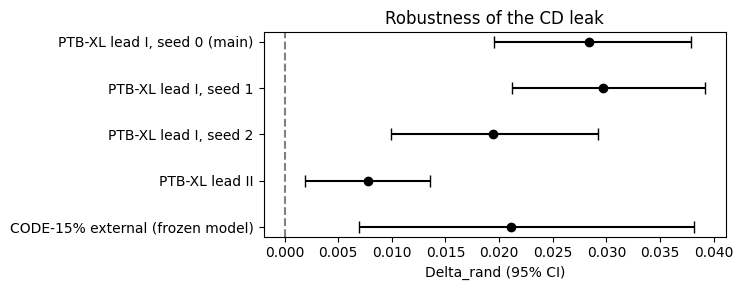

  PASS  Seed runs pass identity check
  PASS  Lead II model passes identity check
  PASS  External CODE-15% test run
  Leak (Delta_rand CI above 0) holds for every seed: YES
  Leak (Delta_rand CI above 0) holds for lead II: YES
  Leak (Delta_rand CI above 0) holds for external CODE-15%: YES
GO: experiments complete. Next is Phase 6 (paper figures and writing).


In [12]:
import matplotlib.pyplot as plt
rob = pd.DataFrame([
    {"setting": "PTB-XL lead I, seed 0 (main)", "est": seeds.loc[0, "Delta_rand"], "lo": seeds.loc[0, "rand_ci_low"], "hi": seeds.loc[0, "rand_ci_high"]},
    *[{"setting": f"PTB-XL lead I, seed {s}", "est": seeds.loc[s, "Delta_rand"], "lo": seeds.loc[s, "rand_ci_low"],
       "hi": seeds.loc[s, "rand_ci_high"]} for s in PLAN5["seeds"]],
    {"setting": "PTB-XL lead II", "est": tab2.loc["Delta_rand", "estimate"], "lo": tab2.loc["Delta_rand", "ci_low"], "hi": tab2.loc["Delta_rand", "ci_high"]},
    {"setting": "CODE-15% external (frozen model)", "est": tab3.loc["Delta_rand", "estimate"], "lo": tab3.loc["Delta_rand", "ci_low"], "hi": tab3.loc["Delta_rand", "ci_high"]},
]).set_index("setting")
rob.to_csv(f"{OUT}/robustness_Delta_rand.csv")
print(rob.round(4).to_string())

fig, ax = plt.subplots(figsize=(7.5, 3))
yy = np.arange(len(rob))[::-1]
ax.errorbar(rob["est"], yy, xerr=[rob["est"] - rob["lo"], rob["hi"] - rob["est"]], fmt="o", capsize=4, color="black")
ax.axvline(0, ls="--", c="grey"); ax.set_yticks(yy); ax.set_yticklabels(rob.index)
ax.set_xlabel("Delta_rand (95% CI)"); ax.set_title(f"Robustness of the {PRIMARY} leak")
plt.tight_layout(); plt.savefig(f"{PATHS['figures']}/figure4_robustness.png", dpi=200); plt.show()

checks = {"Seed runs pass identity check": SEEDS_ID_OK, "Lead II model passes identity check": LEAD2_ID_OK,
          "External CODE-15% test run": len(tab3) == 3}
for k, v in checks.items():
    print(f"  {'PASS' if v else 'FAIL'}  {k}")
holds = {"every seed": SEEDS_HOLD, "lead II": bool(tab2.loc["Delta_rand", "ci_low"] > 0),
         "external CODE-15%": bool(tab3.loc["Delta_rand", "ci_low"] > 0)}
for k, v in holds.items():
    print(f"  Leak (Delta_rand CI above 0) holds for {k}: {'YES' if v else 'NO'}")
json.dump({"phase": 5, "go": all(checks.values()), "checks": checks, "holds": holds,
           "seeds": seeds.round(4).reset_index().to_dict("records"), "lead_II": tab2.round(4).reset_index().to_dict("records"),
           "external": EXT, "environment": ecfg.environment()},
          open(f"{PATHS['gates']}/gate_5.json", "w"), indent=2, default=str)
print("GO: experiments complete. Next is Phase 6 (paper figures and writing)." if all(checks.values())
      else "NO-GO: fix the FAIL lines above.")

In [13]:
from google.colab import drive
drive.mount("/content/drive")

import os, sys, json, importlib
from pathlib import Path
import numpy as np, pandas as pd, torch

PROJECT = Path("/content/drive/MyDrive/ecg_leak")
sys.path.insert(0, str(PROJECT / "src"))
import ecgleak.config as ecfg, ecgleak.leakage as LK
for mod in (ecfg, LK):
    importlib.reload(mod)
CFG = ecfg.load(str(PROJECT / "config.yaml"))
PATHS = CFG["paths"]
G = {k: json.load(open(f"{PATHS['gates']}/gate_{k}.json")) for k in [1, 2, 3, 4, 5]}
assert all(G[k]["go"] for k in G), "Every phase gate (1-5) must be GO before Phase 6"
PLAN = json.load(open(f"{PATHS['gates']}/phase3_plan.json"))
R4, R5 = f"{PATHS['results']}/phase4", f"{PATHS['results']}/phase5"
PAPER = f"{PATHS['results']}/paper"
os.makedirs(PAPER, exist_ok=True)
PRIMARY = CFG["leakage"]["primary"]
SUPER = ["NORM", "MI", "STTC", "CD", "HYP"]
NAMES = {"CD": "Conduction disturbance", "MI": "Myocardial infarction", "STTC": "ST/T change", "HYP": "Hypertrophy"}

import matplotlib.pyplot as plt
plt.rcParams.update({"font.size": 9, "axes.spines.top": False, "axes.spines.right": False,
                     "savefig.dpi": 300, "savefig.bbox": "tight", "font.family": "DejaVu Sans"})
def save(fig, name):
    for ext in ("pdf", "png"):
        fig.savefig(f"{PAPER}/{name}.{ext}")
    plt.show()
print("All five gates GO. Paper outputs ->", PAPER)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Root /content/drive/MyDrive/ecg_leak | raw data /content/drive/MyDrive/PTB-XL | seed 0 | Python 3.13.16 | torch 2.11.0+cu130 | GPU Tesla T4
All five gates GO. Paper outputs -> /content/drive/MyDrive/ecg_leak/results/paper


Cell 6.1: Corrected significance test for the main result

What: re-tests the main CD result from the lockbox scores saved in Phase 3, in two ways:

the template against each of the 5 untrained copies separately, reporting all 5 p-values and the largest one;
a p-value taken directly from the bootstrap, so it matches the confidence interval.

Why: this fixes the mismatch I flagged. The old permutation test compared the template against the 5 copies averaged together, which acts like a stronger “ensemble” opponent. If the template beats every single copy, the claim is airtight, and the largest p-value is the conservative one to report.

In [14]:
sc = np.load(f"{PATHS['results']}/lockbox_scores_{PRIMARY}.npz")
y = sc["y"]
untr = sorted(k for k in sc.files if k.startswith("untrained_"))
tid = sc["identity_template"]
per_copy = []
for k in untr:
    per_copy.append({"comparison": f"template vs {k}", "auroc_template": LK.auc(y, tid), "auroc_copy": LK.auc(y, sc[k]),
                     "delta": LK.auc(y, tid) - LK.auc(y, sc[k]),
                     "p_perm": LK.paired_permutation(y, tid, sc[k], PLAN["n_perm"], CFG["seed"])})
per_copy = pd.DataFrame(per_copy).set_index("comparison")
boot = LK.paired_bootstrap(y, {k: sc[k] for k in ["identity_template", *untr]}, PLAN["n_boot"], CFG["seed"])
d = boot["identity_template"] - np.mean([boot[k] for k in untr], axis=0)
p_boot = float(min(1.0, 2 * min((d <= 0).mean(), (d >= 0).mean()) + 1 / len(d)))
MAIN_TEST = {"Delta_rand": float(LK.auc(y, tid) - np.mean([LK.auc(y, sc[k]) for k in untr])),
             "ci_low": float(np.percentile(d, 2.5)), "ci_high": float(np.percentile(d, 97.5)),
             "p_bootstrap_two_sided": p_boot, "p_perm_max_over_copies": float(per_copy["p_perm"].max()),
             "n_lockbox": int(len(y)), "n_pos": int(y.sum())}
per_copy.to_csv(f"{PAPER}/main_test_per_untrained_copy.csv")
json.dump(MAIN_TEST, open(f"{PAPER}/main_test.json", "w"), indent=2)
print(per_copy.round(4).to_string())
print("\nMain result,", PRIMARY, "vs NORM:", json.dumps({k: round(v, 4) if isinstance(v, float) else v for k, v in MAIN_TEST.items()}))
print("Interpretation: the template must beat EVERY untrained copy; the largest of the 5 p-values is the conservative one.")

                         auroc_template  auroc_copy   delta  p_perm
comparison                                                         
template vs untrained_0          0.8665      0.8352  0.0312   0.001
template vs untrained_1          0.8665      0.8454  0.0211   0.001
template vs untrained_2          0.8665      0.8349  0.0316   0.001
template vs untrained_3          0.8665      0.8349  0.0316   0.001
template vs untrained_4          0.8665      0.8400  0.0265   0.001

Main result, CD vs NORM: {"Delta_rand": 0.0284, "ci_low": 0.0195, "ci_high": 0.0379, "p_bootstrap_two_sided": 0.0005, "p_perm_max_over_copies": 0.001, "n_lockbox": 3372, "n_pos": 1072}
Interpretation: the template must beat EVERY untrained copy; the largest of the 5 p-values is the conservative one.


Cell 6.3: Table 2: does the biometric work?

What: identity EER and rank-1 accuracy for every model: the baseline, ArcFace with 3 seeds, Siamese, lead II, and the frozen model on CODE-15%.
Why: the leak claim only matters if the biometric actually works. This table proves it does, including on a new population.

In [15]:
s4 = {r["model"]: r for r in G[4]["siamese"]}
seeds = {r["seed"]: r for r in G[5]["seeds"]}
ext = G[5]["external"].get("identity_transfer", {})
t2 = pd.DataFrame([
    {"Model": "Median-beat nearest match (baseline)", "Data": "PTB-XL lead I", "EER": G[2]["identity_baseline"]["eer"],
     "Rank-1": G[2]["identity_baseline"]["rank1"]},
    *[{"Model": f"CNN-Transformer + ArcFace, seed {s}", "Data": "PTB-XL lead I", "EER": seeds[s]["eer"],
       "Rank-1": G[3]["identity"]["rank1"] if s == 0 else np.nan} for s in sorted(seeds)],
    {"Model": "CNN-Transformer + Siamese contrastive", "Data": "PTB-XL lead I",
     "EER": s4["Siamese contrastive (BiomECG-style)"]["eer"], "Rank-1": s4["Siamese contrastive (BiomECG-style)"]["rank1"]},
    {"Model": "CNN-Transformer + ArcFace", "Data": "PTB-XL lead II",
     "EER": torch.load(f"{PATHS['runs']}/id_lead2_s0/best.pt", map_location="cpu", weights_only=False)["eer"], "Rank-1": np.nan},
    {"Model": "ArcFace seed 0, frozen (transfer)", "Data": "CODE-15% repeat patients",
     "EER": ext.get("eer", np.nan), "Rank-1": ext.get("rank1", np.nan)},
    {"Model": "Median-beat nearest match (baseline)", "Data": "CODE-15% repeat patients",
     "EER": ext.get("baseline_eer", np.nan), "Rank-1": np.nan},
]).set_index("Model")
t2.to_csv(f"{PAPER}/table2_identity.csv")
open(f"{PAPER}/table2_identity.tex", "w").write(t2.to_latex(float_format="%.3f", na_rep="--", escape=True))
print("Table 2. Identity verification on people not seen in training (lower EER is better)\n" + t2.round(3).to_string())

Table 2. Identity verification on people not seen in training (lower EER is better)
                                                           Data    EER  Rank-1
Model                                                                         
Median-beat nearest match (baseline)              PTB-XL lead I  0.190   0.432
CNN-Transformer + ArcFace, seed 0                 PTB-XL lead I  0.059   0.633
CNN-Transformer + ArcFace, seed 1                 PTB-XL lead I  0.054     NaN
CNN-Transformer + ArcFace, seed 2                 PTB-XL lead I  0.060     NaN
CNN-Transformer + Siamese contrastive             PTB-XL lead I  0.068   0.538
CNN-Transformer + ArcFace                        PTB-XL lead II  0.054     NaN
ArcFace seed 0, frozen (transfer)      CODE-15% repeat patients  0.156   0.620
Median-beat nearest match (baseline)   CODE-15% repeat patients  0.204     NaN


Cell 6.4: Table 3: the leak, for all four diseases

What: for CD, MI, STTC and HYP, it gives the AUROC of each representation and the three gains with 95% CIs, plus the corrected p-value for Δ_rand.
Why: this is the paper’s main results table

In [16]:
tasks = pd.read_csv(f"{R4}/table3_all_tasks.csv")
aucs = pd.read_csv(f"{R4}/aucs_all_tasks.csv").set_index("task")
untr_cols = [c for c in aucs.columns if c.startswith("untrained_")]
fmt = lambda r: f"{r['estimate']:+.3f} [{r['ci_low']:+.3f}, {r['ci_high']:+.3f}]"
rows = []
for task, g in tasks.groupby("task", sort=False):
    g = g.set_index("gain"); a = aucs.loc[task]
    rows.append({"Task": task, "Positives / negatives": f"{int(g['n_pos'].iloc[0])} / {int(g['n_neg'].iloc[0])}",
                 "AUROC template": a["identity_template"], "AUROC untrained (mean of 5)": a[untr_cols].mean(),
                 "AUROC raw beat": a["raw_median_beat"], "AUROC age+sex": a["age_sex"],
                 "Delta_rand [95% CI]": fmt(g.loc["Delta_rand"]), "Delta_raw [95% CI]": fmt(g.loc["Delta_raw"]),
                 "Delta_demo [95% CI]": fmt(g.loc["Delta_demo"]), "p (BH), Delta_rand": g.loc["Delta_rand", "p_BH"]})
t3 = pd.DataFrame(rows).set_index("Task")
t3.to_csv(f"{PAPER}/table3_leakage.csv")
open(f"{PAPER}/table3_leakage.tex", "w").write(t3.to_latex(float_format="%.3f", escape=True))
print("Table 3. Diagnostic leakage on the lockbox (attacker: logistic regression)\n" + t3.round(3).to_string())

Table 3. Diagnostic leakage on the lockbox (attacker: logistic regression)
             Positives / negatives  AUROC template  AUROC untrained (mean of 5)  AUROC raw beat  AUROC age+sex      Delta_rand [95% CI]       Delta_raw [95% CI]      Delta_demo [95% CI]  p (BH), Delta_rand
Task                                                                                                                                                                                                         
CD vs NORM             1072 / 2300           0.866                        0.838           0.823          0.758  +0.028 [+0.020, +0.038]  +0.044 [+0.029, +0.058]  +0.130 [+0.113, +0.146]               0.002
MI vs NORM             1124 / 2300           0.880                        0.863           0.858          0.782  +0.017 [+0.010, +0.024]  +0.022 [+0.012, +0.033]  +0.122 [+0.108, +0.137]               0.015
STTC vs NORM           1102 / 2300           0.935                        0.922           0.932      

Cell 6.5: Table 4: robustness

What: Δ_rand for CD in every setting tested: 3 seeds, lead II, CODE-15%, the MLP and kNN attackers, and the Siamese biometric. It notes whether each CI excludes zero.
Why: one table answers “is it real?” for reviewers.

In [17]:
rob = pd.read_csv(f"{R5}/robustness_Delta_rand.csv").rename(columns={"setting": "Setting"})
att = pd.read_csv(f"{R4}/attackers_{PRIMARY}.csv")
siam = pd.read_csv(f"{R4}/siamese_vs_arcface.csv")
extra = [{"Setting": f"Attacker: {r['attacker'].upper()}", "est": r["Delta_rand"], "lo": r["ci_low"], "hi": r["ci_high"]}
         for _, r in att.iterrows() if r["attacker"] != "logreg"]
extra += [{"Setting": "Biometric: Siamese contrastive", "est": r["Delta_rand"], "lo": r["ci_low"], "hi": r["ci_high"]}
          for _, r in siam.iterrows() if r["model"].startswith("Siamese")]
t4 = pd.concat([rob, pd.DataFrame(extra)], ignore_index=True).set_index("Setting")
t4["Delta_rand [95% CI]"] = [f"{e:+.3f} [{l:+.3f}, {h:+.3f}]" for e, l, h in zip(t4["est"], t4["lo"], t4["hi"])]
t4["CI excludes 0"] = np.where(t4["lo"] > 0, "yes", "no")
t4[["Delta_rand [95% CI]", "CI excludes 0"]].to_csv(f"{PAPER}/table4_robustness.csv")
open(f"{PAPER}/table4_robustness.tex", "w").write(t4[["Delta_rand [95% CI]", "CI excludes 0"]].to_latex(escape=True))
print(f"Table 4. Robustness of the {PRIMARY} leak (Delta_rand)\n" + t4[["Delta_rand [95% CI]", "CI excludes 0"]].to_string())

Table 4. Robustness of the CD leak (Delta_rand)
                                      Delta_rand [95% CI] CI excludes 0
Setting                                                                
PTB-XL lead I, seed 0 (main)      +0.028 [+0.020, +0.038]           yes
PTB-XL lead I, seed 1             +0.030 [+0.021, +0.039]           yes
PTB-XL lead I, seed 2             +0.019 [+0.010, +0.029]           yes
PTB-XL lead II                    +0.008 [+0.002, +0.014]           yes
CODE-15% external (frozen model)  +0.021 [+0.007, +0.038]           yes
Attacker: MLP                     +0.012 [+0.003, +0.023]           yes
Attacker: KNN                     +0.046 [+0.034, +0.058]           yes
Biometric: Siamese contrastive    +0.017 [+0.010, +0.025]           yes


Cell 6.6: Figure 1: the leak, all diseases, all three gains

What: three side-by-side forest plots, one per gain: against the untrained network, against the raw heartbeat, and beyond age and sex. Each shows all four diseases with their CIs.
Why: the paper’s headline figure. A reader sees in one glance that every disease sits to the right of zero.

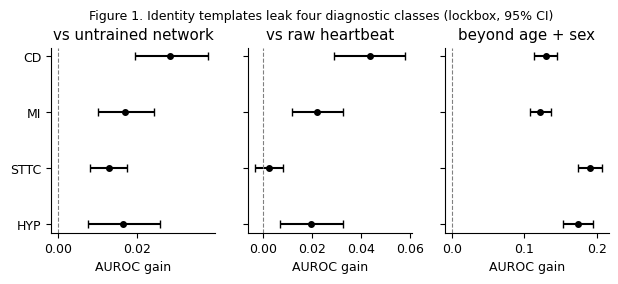

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(7.2, 2.4), sharey=True)
task_order = list(t3.index)
yy = np.arange(len(task_order))[::-1]
for ax, gain, title in zip(axes, ["Delta_rand", "Delta_raw", "Delta_demo"],
                           ["vs untrained network", "vs raw heartbeat", "beyond age + sex"]):
    g = tasks[tasks.gain == gain].set_index("task").loc[task_order]
    ax.errorbar(g["estimate"], yy, xerr=[g["estimate"] - g["ci_low"], g["ci_high"] - g["estimate"]],
                fmt="o", ms=4, capsize=3, color="black")
    ax.axvline(0, ls="--", lw=0.8, color="grey")
    ax.set_title(title); ax.set_xlabel("AUROC gain")
axes[0].set_yticks(yy); axes[0].set_yticklabels([t.split(" ")[0] for t in task_order])
fig.suptitle("Figure 1. Identity templates leak four diagnostic classes (lockbox, 95% CI)", fontsize=9, y=1.04)
save(fig, "figure1_leakage_all_tasks")

Cell 6.7: Figure 2: what drives the leak (H3 and H5)

What: two panels:

(a) identity EER against Δ_rand across training checkpoints: the better the biometric, the larger the leak;
(b) disease persistence across visits against Δ_rand, labelled as descriptive because there are only 4 points.

Why: this moves the paper from “it leaks” to “why it leaks”: the leak is a side effect of making a good biometric.

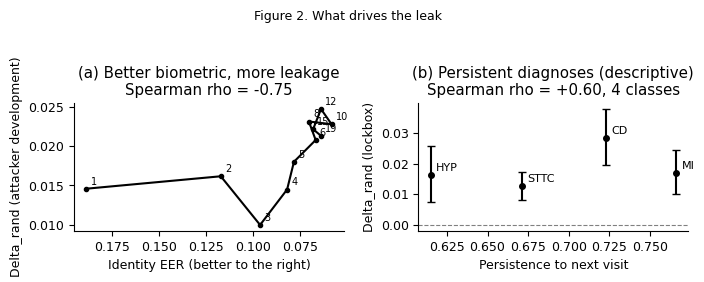

In [19]:
coup = pd.read_csv(f"{R4}/h3_coupling.csv")
h5 = pd.read_csv(f"{R4}/h5_persistence_vs_leak.csv", index_col=0)
fig, ax = plt.subplots(1, 2, figsize=(7.2, 2.6))
ax[0].plot(coup["eer"], coup["Delta_rand_dev"], "-o", ms=3, color="black")
for _, r in coup.iterrows():
    ax[0].annotate(int(r["epoch"]), (r["eer"], r["Delta_rand_dev"]), xytext=(3, 3), textcoords="offset points", fontsize=7)
ax[0].invert_xaxis(); ax[0].set_xlabel("Identity EER (better to the right)"); ax[0].set_ylabel("Delta_rand (attacker development)")
ax[0].set_title(f"(a) Better biometric, more leakage\nSpearman rho = {G[4]['H3_spearman_eer_vs_leak']:+.2f}")
ax[1].errorbar(h5["persistence"], h5["estimate"], yerr=[h5["estimate"] - h5["ci_low"], h5["ci_high"] - h5["estimate"]],
               fmt="o", ms=4, capsize=3, color="black")
for c, r in h5.iterrows():
    ax[1].annotate(c, (r["persistence"], r["estimate"]), xytext=(4, 3), textcoords="offset points", fontsize=8)
ax[1].axhline(0, ls="--", lw=0.8, color="grey")
ax[1].set_xlabel("Persistence to next visit"); ax[1].set_ylabel("Delta_rand (lockbox)")
ax[1].set_title(f"(b) Persistent diagnoses (descriptive)\nSpearman rho = {G[4]['H5_spearman_persistence_vs_leak']:+.2f}, 4 classes")
fig.suptitle("Figure 2. What drives the leak", fontsize=9, y=1.06)
plt.tight_layout(); save(fig, "figure2_coupling_persistence")

6.8: Figures 3 and 4: robustness and attribution check

What:

Figure 3 is a forest plot of all the robustness settings from Table 4.
Figure 4 shows box plots of attribution overlap for identity against diagnosis, compared with the two nulls (H4).

Why: Figure 3 shows the leak survives every change. Figure 4 shows the repaired HPOS check works: real overlap clearly sits above both nulls.

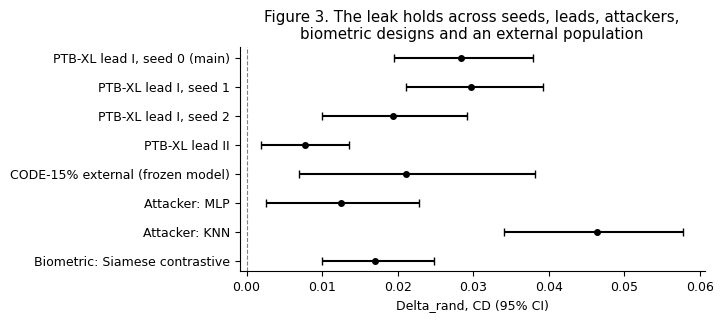

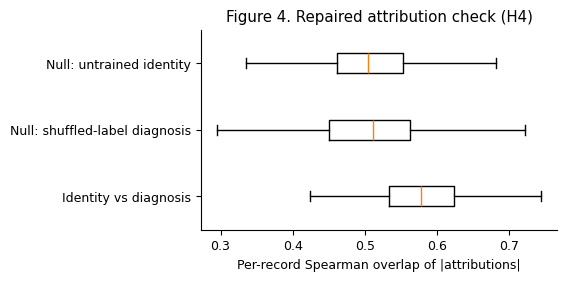

In [20]:
fig, ax = plt.subplots(figsize=(6.0, 2.9))
yy = np.arange(len(t4))[::-1]
ax.errorbar(t4["est"], yy, xerr=[t4["est"] - t4["lo"], t4["hi"] - t4["est"]], fmt="o", ms=4, capsize=3, color="black")
ax.axvline(0, ls="--", lw=0.8, color="grey"); ax.set_yticks(yy); ax.set_yticklabels(t4.index)
ax.set_xlabel(f"Delta_rand, {PRIMARY} (95% CI)")
ax.set_title("Figure 3. The leak holds across seeds, leads, attackers,\nbiometric designs and an external population")
save(fig, "figure3_robustness")

ov = pd.read_csv(f"{R4}/h4_attribution_overlap.csv")
fig, ax = plt.subplots(figsize=(4.6, 2.6))
lab = {"identity_vs_diagnosis": "Identity vs diagnosis", "null_identity_vs_shuffled_diagnosis": "Null: shuffled-label diagnosis",
       "null_untrained_vs_diagnosis": "Null: untrained identity"}
ax.boxplot([ov[c].dropna() for c in lab], vert=False, showfliers=False)
ax.set_yticks([1, 2, 3]); ax.set_yticklabels(list(lab.values()))
ax.set_xlabel("Per-record Spearman overlap of |attributions|")
ax.set_title("Figure 4. Repaired attribution check (H4)")
save(fig, "figure4_attribution_overlap")

l 6.9: One file with every number for the paper

What: collects every number the paper needs into results/paper/paper_numbers.json: data sizes, identity results, the main test, all diseases, H3–H5, robustness and the external test. It also prints the summary.
Why: every number in the paper comes from this one file and nothing is typed by hand, so the text, the tables and the code can never disagree.

In [21]:
summary = {
    "data": {"records": G[1]["records"], "patients": G[1]["patients"], "qc_pass": G[1]["qc_pass"]},
    "identity": {"baseline_eer": G[2]["identity_baseline"]["eer"], "arcface_seed0": G[3]["identity"],
                 "seeds_eer": {r["seed"]: r["eer"] for r in G[5]["seeds"]}, "transfer_code15": G[5]["external"].get("identity_transfer")},
    "main_result": MAIN_TEST, "main_gains": G[3]["gains"], "H1": G[3]["H1_supported"], "H2": G[3]["H2_supported"],
    "all_tasks": t3.reset_index().to_dict("records"),
    "H3": {"rho": G[4]["H3_spearman_eer_vs_leak"], "p": G[4]["H3_p"], "supported": G[4]["H3_supported"]},
    "H4": {"supported": G[4]["H4_supported"], "detail": G[4]["H4_detail"]},
    "H5_rho": G[4]["H5_spearman_persistence_vs_leak"],
    "robustness": t4[["est", "lo", "hi"]].round(4).reset_index().to_dict("records"),
    "external_leak": G[5]["external"]["leak"],
}
json.dump(summary, open(f"{PAPER}/paper_numbers.json", "w"), indent=2, default=str)
print(json.dumps(summary, indent=1, default=str)[:6000])
print("\nSaved to results/paper/: tables 1-4 (.csv + .tex), figures 1-4 (.pdf + .png), main_test.json, paper_numbers.json")

{
 "data": {
  "records": 21799,
  "patients": 18869,
  "qc_pass": 21798
 },
 "identity": {
  "baseline_eer": 0.1904577014434497,
  "arcface_seed0": {
   "eer": 0.05941772004717377,
   "rank1": 0.6328671328671329,
   "n_enrolled": 422,
   "n_probes": 572
  },
  "seeds_eer": {
   "0": 0.0594,
   "1": 0.054,
   "2": 0.0595
  },
  "transfer_code15": {
   "eer": 0.1563556763285024,
   "rank1": 0.6195652173913043,
   "baseline_eer": 0.20389492753623195,
   "n_patients": 181
  }
 },
 "main_result": {
  "Delta_rand": 0.028407121998702323,
  "ci_low": 0.019508003279656523,
  "ci_high": 0.03789512368140582,
  "p_bootstrap_two_sided": 0.0005,
  "p_perm_max_over_copies": 0.000999000999000999,
  "n_lockbox": 3372,
  "n_pos": 1072
 },
 "main_gains": [
  {
   "gain": "Delta_rand",
   "estimate": 0.028407121998702323,
   "ci_low": 0.019508003279656523,
   "ci_high": 0.03789512368140582,
   "ci_halfwidth": 0.00919356020087465,
   "p_perm": 0.000999000999000999
  },
  {
   "gain": "Delta_raw",
   "esti